# MADGDF — post-review re-experimentation (Colab)

Self-contained rerun of the evaluation under the conditions the editorial review
made mandatory:

1. **Time-causal graph construction** — the graph at step *t* is built from logs
   with `time_bin <= t` only, with an assertion that fails loudly if the edge
   sequence is ever non-monotone.
2. **Trained GCN** — the encoder is trained by self-supervised **link prediction**
   on the clean warm-up graph, not left at random initialisation.
3. **Adaptive canary-evasion adversary** — markers stripped at
   *e* ∈ {0, 0.25, 0.50, 0.75, 1.00}.
4. **Non-degenerate statistics** — bootstrap CIs and Wilcoxon, with zero-variance
   cases reported as deterministic rather than as `p=0, d=-5e12`.

**Runtime:** ~5–8 minutes on a free CPU runtime (`--runs 20`, five datasets).
No GPU needed, no API keys, no tokens.

**Datasets.** ToolBench, τ-bench and SWE-agent are fetched from their upstream
repositories and the resolved commit SHA is recorded in `provenance.json`.

**Read before citing these numbers.** All three real datasets are *single-agent*
benchmarks. Their behavioural features are real; the communication topology and
the compromise labels are synthetic overlays, because no public dataset of real
multi-agent communication with labelled compromise exists. These runs test
whether detection holds on a real behavioural substrate — they are **not**
evidence about real attacks observed in the wild.

*Runtime > Run all.*

## 1 · Dependencies

In [ ]:
!pip -q install torch torch_geometric networkx pandas scipy matplotlib
print("dependencies installed")

dependencies installed


## 2 · Fetch the real trajectory datasets

Cloned from the canonical upstream repositories. ToolBench uses a sparse
checkout so only the example trajectories are pulled rather than the full
dataset repository.

In [ ]:
import os, shutil, subprocess, textwrap

# Clear any dataset cache left behind by an earlier failed run in this session.
# A half-populated or wrongly-scoped /tmp/madgdf_* directory is detected and
# rebuilt by the acquisition code, but clearing it here makes a re-run after a
# failure start from a clean state rather than relying on that recovery path.
for _stale in ("madgdf_toolbench", "madgdf_taubench", "madgdf_sweagent"):
    shutil.rmtree(os.path.join("/tmp", _stale), ignore_errors=True)

def clone(url, dest, sparse=None):
    if os.path.isdir(dest):
        print(f"  {dest}: already present"); return
    cmd = ["git", "clone", "--depth", "1", "--quiet"]
    if sparse:
        cmd += ["--filter=blob:none", "--sparse"]
    cmd += [url, dest]
    try:
        subprocess.run(cmd, check=True, capture_output=True, timeout=900)
        if sparse:
            subprocess.run(["git", "-C", dest, "sparse-checkout", "set", sparse],
                           check=True, capture_output=True, timeout=600)
        sha = subprocess.run(["git", "-C", dest, "rev-parse", "HEAD"],
                             check=True, capture_output=True, text=True).stdout.strip()
        print(f"  {dest}: cloned @ {sha[:10]}")
    except Exception as e:
        print(f"  {dest}: FAILED -- {e}")

print("fetching upstream datasets:")
clone("https://github.com/OpenBMB/ToolBench",      "toolbench_sample_data", sparse="data_example")
clone("https://github.com/sierra-research/tau-bench", "taubench_sample_data")
clone("https://github.com/SWE-agent/SWE-agent",    "sweagent_sample_data", sparse="trajectories")

# Verify each clone contains files the adapters can actually read. A clone that
# succeeds but is scoped to the wrong subdirectory looks fine here and fails
# much later with an opaque "0 trajectories loaded"; checking now names the
# real problem at the point it occurs.
import glob
ok = True
for d, pat in [("toolbench_sample_data", "data_example/answer/*/*.json"),
               ("taubench_sample_data", "historical_trajectories/*.json"),
               ("sweagent_sample_data", "trajectories/**/*.traj")]:
    n = len(glob.glob(os.path.join(d, pat), recursive=True))
    print(f"  {d}: {n} files matching {pat}")
    ok &= n > 0
print("\nall datasets usable" if ok else
      "\nWARNING: at least one dataset is empty -- the run below will stop and say which")

fetching upstream datasets:
  toolbench_sample_data: cloned @ d56fdd89fa
  taubench_sample_data: cloned @ 59a200c6d5
  sweagent_sample_data: cloned @ 3ea751c087
  toolbench_sample_data: 15 files matching data_example/answer/*/*.json
  taubench_sample_data: 4 files matching historical_trajectories/*.json
  sweagent_sample_data: 19 files matching trajectories/**/*.traj

all datasets usable


## 3 · The `madgdf` package

In [ ]:
import os
os.makedirs('madgdf', exist_ok=True)

MODULES = {}

MODULES['__init__.py'] = r''''''

MODULES['memory.py'] = r'''"""madgdf.memory -- shadow-memory canary trap (Algorithm 2, Section 3.2/3.4)."""

CANARY_TOKEN = "CANARY_KEY_9982_EXPLOIT"


class ShadowMemoryTrap:
    """Canary-based memory-integrity verification module. Any retrieval that
    contains a canary token immediately raises an alert and marks a breach,
    exactly as described in Section 3.2 ('Shadow Memory')."""

    def __init__(self, canary_tokens=None):
        self.canary_tokens = canary_tokens or {CANARY_TOKEN}
        self.alert_log = []
        self.trigger_count = 0

    def inspect_retrieval(self, agent_id, retrieved_chunks):
        for chunk in retrieved_chunks:
            for token in self.canary_tokens:
                if token in str(chunk):
                    self.trigger_count += 1
                    msg = f"[CANARY ALERT] Agent-{agent_id} retrieved protected token: {token}"
                    self.alert_log.append(msg)
                    return True
        return False
'''

MODULES['enforcement.py'] = r'''"""
madgdf.enforcement -- isolation decision logic (Section 3.1's "madgdf.enforcement"
module, Section 3.3's "Combined Decision").

Extracted out of madgdf.orchestrator so the code's module layout matches what
Section 3.1 of the paper describes: gnn / memory / core (orchestrator) /
enforcement as four cooperating modules, with isolation decisions triggered
here rather than inline inside the orchestrator's step loop.

A node is flagged for isolation when EITHER:
  - its divergence has exceeded the calibrated threshold tau for
    `persistence` consecutive steps (a single-step spike is not treated as
    sufficient evidence -- see the module-level note in orchestrator.py for
    why), OR
  - a canary token was found in its retrieval this step.
"""
import numpy as np


def decide_breach(node_divergence, tau, consec_exceed, persistence, canary_flag, use_gnn=True):
    """Update the per-node consecutive-exceedance counters and return the
    combined breach decision for this step.

    Returns
    -------
    node_breach : bool ndarray, shape (num_nodes,)
    consec_exceed : int ndarray, shape (num_nodes,) -- updated counters, to
        be passed back in on the next call.
    """
    exceeds = (node_divergence > tau) if use_gnn else np.zeros_like(consec_exceed, dtype=bool)
    consec_exceed = np.where(exceeds, consec_exceed + 1, 0)
    div_flag = consec_exceed >= persistence
    node_breach = div_flag | canary_flag
    return node_breach, consec_exceed
'''

MODULES['data_generation.py'] = r'''"""
SwarmBench-2026 synthetic corpus generator.

Implements the hybrid synthetic corpus described in Section 4.2 of the MADGDF
paper: raw material analogous to SEC-bench (tool-use traces), AgentWebBench
(multi-agent coordination logs) and the Open RAG Benchmark (retrieval
documents) is synthetically combined into a corpus of heterogeneous
interaction logs, with adversarial content injected into 15% of interaction
sequences and 5% of long-term-memory retrieval chunks seeded with the
cryptographic canary token, split 70/15/15 into train/validation/adversarial
test.

NOTE ON SCALE: the paper describes ~1.2M logs. That exact figure is
reproducible here via `n_logs=1_200_000` (vectorized generation, a few
seconds on commodity hardware). The default in `run_experiment.py` uses a
smaller `n_logs` purely so the whole pipeline (both prototype and scaled
configs, 50 Monte-Carlo runs each) finishes quickly on a laptop / free Colab
CPU runtime -- change `N_LOGS` in run_experiment.py to 1_200_000 to match the
paper's stated corpus size exactly.
"""
import numpy as np
import pandas as pd

CANARY_TOKEN = "CANARY_KEY_9982_EXPLOIT"
SOURCE_POOL = ["SEC-bench", "AgentWebBench", "OpenRAG"]
LOG_TYPES = ["tool_call", "message", "retrieval"]
TOOL_NAMES = ["search", "exec", "write_file", "send_message", "read_memory", "spawn_subagent"]


def generate_swarmbench_corpus(num_agents=32, n_logs=120_000, corruption_ratio=0.20,
                                adversarial_frac=0.15, canary_seed_frac=0.05, seed=42):
    """Generate the SwarmBench-2026-style interaction log corpus.

    Returns
    -------
    df : pd.DataFrame  -- one row per interaction log
    compromised_agents : set[int] -- ground-truth compromised agent ids
    """
    rng = np.random.default_rng(seed)
    n_compromised = max(1, int(round(num_agents * corruption_ratio)))
    compromised_agents = set(rng.choice(num_agents, size=n_compromised, replace=False).tolist())

    agent_ids = rng.integers(0, num_agents, size=n_logs)
    log_types = rng.choice(LOG_TYPES, size=n_logs, p=[0.40, 0.35, 0.25])
    sources = rng.choice(SOURCE_POOL, size=n_logs)
    timestamps = np.sort(rng.uniform(0, 1_000_000, size=n_logs))
    target_agent = rng.integers(0, num_agents, size=n_logs)
    tool_names = rng.choice(TOOL_NAMES, size=n_logs)

    compromised_mask = np.isin(agent_ids, list(compromised_agents))

    # 15% of interaction sequences carry injected adversarial behavior --
    # synchronized sub-goal distribution across compromised agents only.
    is_adversarial = (rng.random(n_logs) < adversarial_frac) & compromised_mask

    # 5% of long-term-memory retrieval chunks are seeded with the canary token,
    # concentrated on compromised agents (deterministic integrity marker),
    # with a small "control" leakage rate into clean agents' streams so the
    # canary is not trivially collinear with the ground-truth label.
    retrieval_mask = (log_types == "retrieval")
    canary_seeded = np.zeros(n_logs, dtype=bool)
    retrieval_idx = np.where(retrieval_mask)[0]
    n_canary = int(len(retrieval_idx) * canary_seed_frac)
    if n_canary > 0:
        canary_idx = rng.choice(retrieval_idx, size=n_canary, replace=False)
        canary_seeded[canary_idx] = True
    canary_seeded = canary_seeded & retrieval_mask & (
        compromised_mask | (rng.random(n_logs) < 0.02)
    )

    content = np.where(
        canary_seeded, CANARY_TOKEN,
        np.where(is_adversarial, "poisoned_procedural_template", "standard_sop_v3.1")
    )

    df = pd.DataFrame({
        "log_id": np.arange(n_logs),
        "timestamp": timestamps,
        "agent_id": agent_ids,
        "target_agent": target_agent,
        "log_type": log_types,
        "source_dataset": sources,
        "tool_name": tool_names,
        "content": content,
        "is_adversarial": is_adversarial,
        "canary_seeded": canary_seeded,
    })

    n = len(df)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)
    df["split"] = "test"
    df.iloc[:n_train, df.columns.get_loc("split")] = "train"
    df.iloc[n_train:n_train + n_val, df.columns.get_loc("split")] = "val"

    return df, compromised_agents


def build_agent_features(df, num_agents, feat_dim=16, seed=42):
    """Aggregate raw logs into fixed-length 16-d behavioral feature vectors per
    agent (Section 4.3): normalized tool-call frequency, memory-access rate,
    inter-agent message volume, and adversarial/canary exposure rates occupy
    explicit dimensions; remaining dimensions carry standardized auxiliary
    behavioral statistics. Both the per-agent rate statistics AND the z-score
    standardization are computed from the TRAIN split only, per Section 4.3
    ("the same scaling parameters were applied to validation and test data").

    FIX: an earlier revision computed these rates from the whole corpus
    (`df.groupby(...)` on all rows) despite already carrying a `train_df`
    variable that was assigned but never used -- the train/val/test split
    had no functional effect anywhere in the pipeline. Rates are now
    genuinely computed from `train_df` only.
    """
    train_df = df[df.split == "train"]
    rng = np.random.default_rng(seed)
    raw = np.zeros((num_agents, feat_dim))

    grouped_train = train_df.groupby("agent_id")
    for aid in range(num_agents):
        sub = grouped_train.get_group(aid) if aid in grouped_train.groups else train_df.iloc[0:0]
        n = max(1, len(sub))
        tool_freq = (sub.log_type == "tool_call").sum() / n
        mem_rate = (sub.log_type == "retrieval").sum() / n
        msg_vol = (sub.log_type == "message").sum() / n
        adv_rate = sub.is_adversarial.mean() if len(sub) else 0.0
        canary_rate = sub.canary_seeded.mean() if len(sub) else 0.0
        aux = rng.normal(0, 1, feat_dim - 5)
        raw[aid] = np.concatenate([[tool_freq, mem_rate, msg_vol, adv_rate, canary_rate], aux])

    # z-score scaler fit on the train-split-derived raw features only, then
    # applied unchanged (same mu/sigma) -- there is nothing further to apply
    # it "to" at the val/test stage in this pipeline, since features here are
    # a single per-agent summary rather than per-row records with separate
    # val/test copies. calibrate_tau() is what actually exercises a
    # validation-only view of agent behavior -- see calibration.py.
    mu = raw.mean(axis=0)
    sigma = raw.std(axis=0) + 1e-9
    feats = (raw - mu) / sigma
    return feats.astype(np.float32)


def build_communication_graph(df, num_agents, target_avg_degree=8):
    """Convert inter-agent message events into an undirected NetworkX graph
    using a communication-frequency threshold (Section 4.3).

    The threshold is chosen automatically (keeping only the highest-frequency
    pairs so the graph reaches `target_avg_degree`) rather than a fixed
    constant. Two failure modes this avoids:

    1. A fixed low threshold (e.g. >=1 message) saturates to a near-complete
       graph once the corpus is large relative to the agent count, which
       over-smooths the GCN (every node aggregates over almost the same
       neighborhood) and makes per-node divergence indistinguishable between
       clean and compromised agents.
    2. Targeting a constant edge PROBABILITY (as the paper's
       nx.erdos_renyi_graph(p=0.25) does) makes average degree grow linearly
       with the agent count -- fine at 32 agents, but at 250 agents it
       produces a graph roughly 8x denser (avg degree ~62 vs ~8), which
       over-smooths the larger configuration's GCN and destabilizes the
       divergence-threshold calibration (observed empirically: FPR collapsed
       to ~95% at the "scaled" config before this fix). Targeting a constant
       AVERAGE DEGREE instead keeps the two configurations comparable, which
       is what Section 4.1 requires ("only changes the constructor arguments...
       ensuring that observed differences arise from scale rather than from
       changes in algorithmic logic")."""
    import networkx as nx
    G = nx.Graph()
    G.add_nodes_from(range(num_agents))
    msg = df[df.log_type == "message"]
    if len(msg) == 0:
        return G
    counts = msg.groupby(["agent_id", "target_agent"]).size().reset_index(name="freq")
    pair_freq = {}
    for row in counts.itertuples(index=False):
        if row.agent_id == row.target_agent:
            continue
        key = tuple(sorted((int(row.agent_id), int(row.target_agent))))
        pair_freq[key] = pair_freq.get(key, 0) + int(row.freq)

    if not pair_freq:
        return G

    max_possible_edges = num_agents * (num_agents - 1) // 2
    target_edges = min(max_possible_edges,
                        max(1, int(round(target_avg_degree * num_agents / 2))))
    sorted_pairs = sorted(pair_freq.items(), key=lambda kv: kv[1], reverse=True)
    for (a, b), _freq in sorted_pairs[:target_edges]:
        G.add_edge(a, b)
    return G
'''

MODULES['real_data_adapter.py'] = r'''"""
madgdf.real_data_adapter -- adapts genuine ToolBench agent trajectories
(https://github.com/OpenBMB/ToolBench, data_example/answer/*/*.json) into
the same 16-dimensional feature format used by the synthetic SwarmBench-2026
pipeline, so the fixed MADGDF pipeline can be run against real agent
telemetry instead of purely synthetic data.

HONEST SCOPE OF WHAT IS REAL HERE, stated explicitly because it matters for
how these results should be read:

  - REAL: the behavioral statistics driving the feature vectors -- number of
    tool-call attempts (query_count), total token usage, number of distinct
    tools available to the agent, task outcome (win/lose), and genuine API
    error frequency (occurrences of "error" and related failure language in
    real tool responses) are all read directly from real ChatGPT-driven
    ToolBench execution trajectories. Nothing about these numbers is
    synthesized.

  - NOT REAL / NECESSARILY SYNTHETIC:
      1. ToolBench is a SINGLE-AGENT tool-use benchmark. There is no
         multi-agent communication in the source data at all, so the
         inter-agent communication graph used here is a synthetic
         Erdos-Renyi-style topology overlaid on top of the real per-agent
         behavioral features -- there is no such thing as a public dataset
         of real multi-agent communication graphs with labeled compromise
         (a point the paper's own Section 4.2 already concedes).
      2. There is no ground-truth "compromised agent" label in ToolBench
         (it is not an attack dataset). Compromise assignment and
         adversarial drift injection are synthetic, applied on top of the
         real feature baseline, using the identical protocol as the
         SwarmBench-2026 experiments (same corruption ratio, same drift
         mechanism) so that the comparison isolates "does detection
         performance hold up when the underlying behavioral substrate is
         real" rather than testing anything about real attacks in the wild.

  - Sample size is small: only 15 real trajectories ship in ToolBench's
    public repository as ready-to-use example data (5 each in G1/G2/G3).
    Results here should be read as a small-sample real-substrate sanity
    check, not as a statistically powered independent benchmark.
"""
import glob
import json
import re

import numpy as np


def load_toolbench_trajectories(repo_path):
    """Return one raw-stats dict per real ToolBench trajectory file."""
    files = sorted(glob.glob(f"{repo_path}/data_example/answer/*/*.json"))
    records = []
    for f in files:
        d = json.load(open(f))
        ag = d.get("answer_generation", {})
        msgs = ag.get("train_messages", [])
        text = json.dumps(msgs)
        records.append({
            "file": f,
            "query_count": ag.get("query_count", 0) or 0,
            "total_tokens": ag.get("total_tokens", 0) or 0,
            "n_funcs": len(ag.get("function", [])),
            "n_messages": len(msgs),
            "error_mentions": len(re.findall(r"error", text, flags=re.IGNORECASE)),
            "win": bool(d.get("win", False)),
        })
    return records


def build_toolbench_features(records, feat_dim=16, seed=42):
    """Build a (num_agents, feat_dim) standardized feature matrix from real
    per-trajectory statistics. The first 5 dimensions carry real signal
    (mirroring the role played by tool_freq/mem_rate/msg_vol/adv_rate/
    canary_rate in the synthetic pipeline); remaining dimensions are
    standardized auxiliary noise, exactly as in `data_generation.build_agent_features`,
    so the two feature spaces are structurally comparable."""
    n = len(records)
    rng = np.random.default_rng(seed)
    raw = np.zeros((n, feat_dim))
    for i, r in enumerate(records):
        tool_freq = r["query_count"] / max(1, r["n_messages"])
        mem_rate = r["n_funcs"] / max(1, r["query_count"])       # tool-catalog breadth per call, proxy for retrieval-like diversity
        msg_vol = r["n_messages"]
        adv_rate = r["error_mentions"] / max(1, r["query_count"])  # genuine API error rate stands in for "adversarial exposure"
        canary_rate = 0.0 if r["win"] else 1.0                    # task failure as a coarse deviation signal
        aux = rng.normal(0, 1, feat_dim - 5)
        raw[i] = np.concatenate([[tool_freq, mem_rate, msg_vol, adv_rate, canary_rate], aux])

    mu = raw.mean(axis=0)
    sigma = raw.std(axis=0) + 1e-9
    feats = (raw - mu) / sigma
    return feats.astype(np.float32)


def build_synthetic_topology(num_agents, target_avg_degree, seed=42):
    """ToolBench has no real inter-agent communication to draw a graph from
    (see module docstring) -- an Erdos-Renyi-style graph with the same
    average-degree target used elsewhere is used here explicitly as a
    disclosed synthetic stand-in, not a real communication topology."""
    import networkx as nx
    p = min(1.0, target_avg_degree / max(1, num_agents - 1))
    return nx.erdos_renyi_graph(n=num_agents, p=p, seed=seed)


# =============================================================================
# tau-bench (Sierra Research) -- real customer-service tool-use agent
# trajectories. https://github.com/sierra-research/tau-bench
#
# HONEST SCOPE: each trajectory is a real completed run of a real LLM
# (GPT-4o or Claude Sonnet 3.5) against tau-bench's simulated retail/airline
# customer-service environment. The tool calls, message counts, task
# outcome (reward), and per-task API cost are all read directly from the
# repository's historical_trajectories/*.json files -- nothing here is
# synthesized. As with ToolBench, this is a single-agent benchmark: there is
# no real inter-agent communication graph, and no ground-truth "compromised
# agent" label, so the communication topology and compromise overlay are
# disclosed synthetic additions, identical in spirit to the ToolBench
# adapter above.
# =============================================================================

def load_taubench_trajectories(repo_path):
    """Return one raw-stats dict per real tau-bench task trajectory,
    pooling all four historical_trajectories files (two models x two
    domains) into a single real-agent population."""
    files = sorted(glob.glob(f"{repo_path}/historical_trajectories/*.json"))
    records = []
    for f in files:
        tag = f.split("/")[-1].replace(".json", "")
        tasks = json.load(open(f))
        for t in tasks:
            records.append({
                "source_file": tag,
                "task_id": t.get("task_id"),
                "reward": float(t.get("reward", 0.0)),
                "num_actions": len(t.get("info", {}).get("task", {}).get("actions", [])),
                "traj_len": len(t.get("traj", [])),
                "user_cost": t.get("info", {}).get("user_cost", 0.0) or 0.0,
            })
    return records


def build_taubench_features(records, feat_dim=16, seed=42):
    """Build a (num_agents, feat_dim) standardized feature matrix from real
    tau-bench task statistics. First 5 dims carry real signal: tool-call
    rate, conversation-length rate, real task-failure rate (1 - reward) as
    the adversarial-exposure proxy, real per-task API cost, and a
    domain/model indicator; remaining dims are standardized auxiliary
    noise, matching the convention used by the other adapters."""
    n = len(records)
    rng = np.random.default_rng(seed)
    raw = np.zeros((n, feat_dim))
    for i, r in enumerate(records):
        tool_freq = r["num_actions"] / max(1, r["traj_len"])
        mem_rate = r["traj_len"] / 50.0                       # conversation-depth proxy, scaled
        msg_vol = r["traj_len"]
        adv_rate = 1.0 - r["reward"]                          # genuine task failure as adversarial-exposure proxy
        canary_rate = min(1.0, r["user_cost"] * 100)          # real per-task API cost, rescaled
        aux = rng.normal(0, 1, feat_dim - 5)
        raw[i] = np.concatenate([[tool_freq, mem_rate, msg_vol, adv_rate, canary_rate], aux])

    mu = raw.mean(axis=0)
    sigma = raw.std(axis=0) + 1e-9
    feats = (raw - mu) / sigma
    return feats.astype(np.float32)


# =============================================================================
# SWE-agent trajectories -- real GitHub issue-resolution agent runs.
# https://github.com/SWE-agent/SWE-agent
#
# HONEST SCOPE: each .traj file is a real recorded agent run attempting to
# fix a real bug in a real open-source repository (e.g. marshmallow-code/
# marshmallow, pydicom/pydicom), including real shell commands, real file
# contents observed, and (where submitted) a real code diff. The bundled
# demonstration/replay trajectories used here do not track token cost or
# API-call counts (both are 0 in the source files), so those fields are
# NOT used; the real signal used is the number of actions taken, the
# conversation/history length, and whether the agent successfully
# submitted a patch (exit_status == "submitted"). As with the other real
# sources, SWE-agent is single-agent, so the communication graph and
# compromise overlay are disclosed synthetic additions.
# =============================================================================

def load_sweagent_trajectories(repo_path):
    files = sorted(glob.glob(f"{repo_path}/trajectories/**/*.traj", recursive=True))
    records = []
    for f in files:
        d = json.load(open(f))
        exit_status = d.get("info", {}).get("exit_status")
        if exit_status is None:
            continue  # excludes non-task test fixtures (e.g. function_calling_simple.traj)
        records.append({
            "file": f,
            "num_actions": len(d.get("trajectory", [])),
            "num_history": len(d.get("history", [])),
            "submitted": bool(d.get("info", {}).get("submission")),
            "exit_status": exit_status,
        })
    return records


def build_sweagent_features(records, feat_dim=16, seed=42):
    """Build a (num_agents, feat_dim) standardized feature matrix from real
    SWE-agent trajectory statistics. First 5 dims carry real signal:
    action rate, history-length rate, task-failure rate (proxy for
    adversarial exposure, since a non-submitted patch is a real behavioral
    deviation), a real action-count-derived proxy in place of unavailable
    cost data, and a constant real-vs-demo indicator; remaining dims are
    standardized auxiliary noise."""
    n = len(records)
    rng = np.random.default_rng(seed)
    raw = np.zeros((n, feat_dim))
    for i, r in enumerate(records):
        tool_freq = r["num_actions"] / max(1, r["num_history"])
        mem_rate = r["num_history"] / 50.0
        msg_vol = r["num_history"]
        adv_rate = 0.0 if r["submitted"] else 1.0
        canary_rate = r["num_actions"] / 25.0                 # real action-count proxy, rescaled
        aux = rng.normal(0, 1, feat_dim - 5)
        raw[i] = np.concatenate([[tool_freq, mem_rate, msg_vol, adv_rate, canary_rate], aux])

    mu = raw.mean(axis=0)
    sigma = raw.std(axis=0) + 1e-9
    feats = (raw - mu) / sigma
    return feats.astype(np.float32)
'''

MODULES['baseline.py'] = r'''"""
Baseline detectors, Section 4.4:

- ParticleFilterBaseline: "a centralized particle-filter style monitor that
  maintains an independent belief state for each agent and raises an alert
  when a local anomaly score exceeds a fixed threshold" -- i.e. NO graph
  message passing, purely local per-agent tracking. This is the primary
  baseline MADGDF is compared against.

The original submitted code had no implementation of this baseline at all
(the "Baseline_Particle" arm just reused the orchestrator with both use_gnn
and use_canary disabled, which is actually the "local threshold, no graph"
ablation, not an independent particle-filter belief tracker). This module
supplies the real thing so the paper's Table 1 / statistical tests compare
against the baseline it describes.

FIX -- compromised-agent consistency: `compromised_agents` is now an explicit
parameter, matching the same fix applied to `orchestrator.py`. An earlier
revision resampled its own compromised set via `random.Random(seed)`,
independent of the RNG stream (`numpy.random.default_rng(seed)`) used by
`data_generation.generate_swarmbench_corpus` to build the corpus and its
features -- same nominal seed, different algorithm, generally different
agents. The baseline must evaluate against the SAME compromised-agent set
the corpus/features were built from for the comparison to be meaningful.
"""
import time
from collections import defaultdict

import numpy as np
import torch


class ParticleFilterBaseline:
    def __init__(self, num_nodes, corruption_ratio, features, compromised_agents,
                 feat_dim=16, alpha=0.3, local_threshold=0.6, drift_scale=0.4,
                 benign_noise_scale=0.0, seed=42):
        self.num_nodes = num_nodes
        self.feat_dim = feat_dim
        self.alpha = alpha
        self.local_threshold = local_threshold
        self.drift_scale = drift_scale
        # FAIRNESS FIX for the post-review comparison: the time-causal MADGDF
        # orchestrator perturbs EVERY agent with small benign behavioural noise
        # each step, which is what gives clean agents any opportunity at all to
        # be falsely flagged. This baseline previously held clean agents'
        # features perfectly constant, so its clean population could not drift
        # and its measured FPR was 0.00% for structural reasons rather than
        # because the detector was more precise. Defaults to 0.0 so the
        # pre-review results stay reproducible; the post-review runner passes
        # the same value the orchestrator uses.
        self.benign_noise_scale = benign_noise_scale

        # FIX: same seeding gap as orchestrator.py -- `seed` previously had
        # no effect on the drift noise's torch RNG stream.
        torch.manual_seed(seed)

        compromised = set(compromised_agents)

        self.features = [torch.tensor(np.asarray(features[i], dtype=np.float32)).unsqueeze(0)
                          for i in range(num_nodes)]
        self.is_compromised = np.array([i in compromised for i in range(num_nodes)])
        self.belief = np.zeros(num_nodes)  # independent per-agent belief state
        self.history = defaultdict(list)

    def simulate_step(self, step_idx):
        start = time.time()
        node_breach = np.zeros(self.num_nodes, dtype=bool)
        poisoned_retrievals = 0

        for i in range(self.num_nodes):
            if self.benign_noise_scale:
                self.features[i] = self.features[i] + \
                    torch.randn(1, self.feat_dim) * self.benign_noise_scale
            if self.is_compromised[i]:
                self.features[i] = self.features[i] + torch.randn(1, self.feat_dim) * self.drift_scale
                poisoned_retrievals += 1
            local_score = torch.norm(self.features[i]).item() / (self.feat_dim ** 0.5)
            # exponentially-weighted belief update, local only (no neighbor info)
            self.belief[i] = self.alpha * local_score + (1 - self.alpha) * self.belief[i]
            node_breach[i] = self.belief[i] > self.local_threshold

        latency = (time.time() - start) * 1000.0
        absorbed = int((self.is_compromised & ~node_breach).sum())
        false_positives = int((~self.is_compromised & node_breach).sum())
        clean_total = int((~self.is_compromised).sum())

        self.history["step"].append(step_idx)
        self.history["latency_ms"].append(latency)
        self.history["breach"].append(int(node_breach.any()))
        self.history["poisoned_retrievals"].append(poisoned_retrievals)
        self.history["absorbed"].append(absorbed)
        self.history["mpar"].append(absorbed / max(1, poisoned_retrievals))
        self.history["fpr"].append(false_positives / max(1, clean_total))
        self.history["false_positives_count"].append(false_positives)
        self.history["clean_total"].append(clean_total)
        # true positives recorded so detection can be scored against actually
        # compromised agents rather than "any alert fired" -- see metrics_v2
        self.history["true_positive_count"].append(
            int((self.is_compromised & node_breach).sum()))
        return self.history

    def run(self, num_steps):
        for s in range(num_steps):
            self.simulate_step(s)
        return self.history
'''

MODULES['temporal_graph.py'] = r'''"""
madgdf.temporal_graph -- strictly time-causal communication-graph construction.

WHY THIS MODULE EXISTS (peer review, Comment 2 / Fatal Flaw "Data Leakage"):

    "The graph construction methodology processes entire message logs at once.
     In a real-time detection setting, future communications cannot inform
     current state graph representations. This temporal look-ahead introduces
     data leakage, rendering all metric curves artificially optimistic."

The reviewer is correct about the previous implementation. In
`data_generation.build_communication_graph`, the graph was built ONCE from the
complete corpus `df` and then held fixed for every simulation step: the
orchestrator's `_edge_index()` returned the same edge set at step 0 as at step
19. An edge between agents u and v that only arose from messages exchanged at
step 18 was therefore already present in the graph the detector used at step 0.
Because the GCN aggregates over neighbourhoods, that is a direct channel for
future information to influence past detection decisions.

This module replaces that with an incremental construction. Logs are binned by
timestamp into `n_steps` contiguous windows, and the graph visible at step t is
built from bins 0..t ONLY:

    G_t = build(logs where time_bin <= t)

so G_0 subset G_1 subset ... subset G_{T-1}, and no edge can appear before the
messages that justify it have occurred. `assert_causal()` verifies this
property directly rather than relying on the construction being read correctly.

ONE CONSEQUENCE WORTH STATING PLAINLY: a time-causal graph is sparser early in
the run (little history has accumulated), so early-step embeddings are noisier
than under the leaky construction. Detection latency measured here will
therefore be WORSE than previously reported. That is the point -- the previous
numbers were optimistic for exactly the reason the reviewer identified.
"""
import networkx as nx
import numpy as np
import pandas as pd


def assign_time_bins(df, n_steps, time_col="timestamp"):
    """Partition logs into `n_steps` contiguous time windows by timestamp.

    Uses equal-frequency (quantile) binning rather than equal-width so each
    step carries a comparable number of events; equal-width bins on a
    non-uniform timestamp distribution can leave early steps nearly empty,
    which would confound "the detector saw little history" with "the detector
    saw little traffic".
    """
    ts = df[time_col].to_numpy()
    ranks = np.argsort(np.argsort(ts))
    bins = (ranks * n_steps // max(1, len(ts))).astype(int)
    return np.clip(bins, 0, n_steps - 1)


class TemporalCommunicationGraph:
    """Incremental, strictly causal communication graph.

    Parameters
    ----------
    df : DataFrame with columns agent_id, target_agent, log_type, timestamp
    num_agents : int
    n_steps : int
    target_avg_degree : int
        Edge budget is scaled by the fraction of history observed so far, so
        the graph densifies over time instead of jumping to its final density
        at step 0. Keeping a *degree* target (rather than an edge-probability
        target) is retained from the previous fix: at 250 agents a constant
        edge probability produces a ~8x denser graph than at 32 agents, which
        over-smooths the GCN and destabilises threshold calibration.
    """

    def __init__(self, df, num_agents, n_steps, target_avg_degree=8, causal=True):
        self.num_agents = num_agents
        self.n_steps = n_steps
        self.target_avg_degree = target_avg_degree
        # causal=False reproduces the PRE-REVIEW leaky construction exactly:
        # graph_at(t) returns the final full-log graph for every t, so edges
        # justified only by step-19 messages are already visible at step 0.
        # It exists so the leakage can be QUANTIFIED rather than merely
        # asserted to have been fixed -- a passing causality assertion shows
        # the new pipeline is clean, but says nothing about how much the old
        # one was inflated. `assert_causal()` is not meaningful in this mode
        # and raises if called.
        self.causal = causal

        msg = df[df.log_type == "message"].copy()
        if len(msg) == 0:
            self._pair_freq_by_step = [dict() for _ in range(n_steps)]
            return

        msg["time_bin"] = assign_time_bins(msg, n_steps)

        # cumulative pair frequency per step, built forward in time only
        self._pair_freq_by_step = []
        running = {}
        for t in range(n_steps):
            step_msgs = msg[msg.time_bin == t]
            for row in step_msgs.itertuples(index=False):
                a, b = int(row.agent_id), int(row.target_agent)
                if a == b:
                    continue
                key = (a, b) if a < b else (b, a)
                running[key] = running.get(key, 0) + 1
            self._pair_freq_by_step.append(dict(running))

        self._edges_by_step = self._build_monotone_edge_sets()

    def _build_monotone_edge_sets(self):
        """Edge sets that only ever grow: E_0 subset E_1 subset ... subset E_{T-1}.

        Ranking by cumulative frequency and taking the top-k independently at
        each step does NOT give a monotone sequence: an edge inside the budget
        at step t can be overtaken by other pairs at step t+1 and drop out,
        which would mean the detector "unlearns" a communication it has already
        observed. That is not a causality violation in the leakage sense, but it
        is not a defensible model of an observer's knowledge either, and it made
        `assert_causal` fail -- correctly.

        Edges are therefore accumulated: at each step the budget grows, and the
        highest-ranked not-yet-admitted pairs are added to fill it. Nothing is
        ever removed.
        """
        max_possible = self.num_agents * (self.num_agents - 1) // 2
        edges = []
        current = set()
        prev_budget = 0
        for t in range(self.n_steps):
            pair_freq = self._pair_freq_by_step[t]
            if not pair_freq:
                edges.append(set())
                continue
            frac = (t + 1) / self.n_steps
            budget = int(round(self.target_avg_degree * self.num_agents / 2 * frac))
            budget = max(1, min(max_possible, budget, len(pair_freq)))
            budget = max(budget, prev_budget, len(current))
            prev_budget = budget

            ranked = sorted(pair_freq.items(), key=lambda kv: (-kv[1], kv[0]))
            for (a, b), _f in ranked:
                if len(current) >= budget:
                    break
                current.add((a, b))
            edges.append(set(current))
        return edges

    def graph_at(self, t):
        """Communication graph as observable at step t (bins 0..t only).

        With causal=False this returns the final full-log graph regardless of
        t -- the leaky pre-review behaviour, kept only for the ablation.
        """
        G = nx.Graph()
        G.add_nodes_from(range(self.num_agents))
        idx = (self.n_steps - 1) if not self.causal else t
        G.add_edges_from(self._edges_by_step[idx])
        return G

    def assert_causal(self):
        """Verify G_0 subset G_1 subset ... subset G_{T-1}.

        A monotone edge set is the operational definition of "no future
        information in a past graph" for this construction: an edge present at
        step t must still be present at every later step, and no edge may
        appear at step t that is not justified by messages in bins 0..t.
        Raises AssertionError if violated.
        """
        assert self.causal, (
            "assert_causal() called on a graph built with causal=False -- that "
            "mode deliberately leaks and exists only for the ablation."
        )
        prev = set()
        for t in range(self.n_steps):
            cur = set(self.graph_at(t).edges())
            cur = {(min(a, b), max(a, b)) for a, b in cur}
            missing = prev - cur
            assert not missing, (
                f"causality violation: edges present at step {t-1} vanished at "
                f"step {t}: {sorted(missing)[:5]}"
            )
            # every edge at step t must be backed by messages in bins <= t
            allowed = set(self._pair_freq_by_step[t].keys())
            unjustified = cur - allowed
            assert not unjustified, (
                f"causality violation: edges at step {t} unjustified by history: "
                f"{sorted(unjustified)[:5]}"
            )
            prev = cur
        return True


def warmup_graph(temporal_graph, warmup_steps):
    """Graph observable at the end of a clean warm-up window.

    The reference embedding Z_ref must be captured from pre-corruption
    observations only. Using the final (full-run) graph for Z_ref would
    reintroduce exactly the leakage this module removes, by a different route.
    """
    return temporal_graph.graph_at(max(0, warmup_steps - 1))
'''

MODULES['gnn_trained.py'] = r'''"""
madgdf.gnn_trained -- self-supervised GCN encoder trained by link prediction.

WHY THIS MODULE EXISTS (peer review, Comment 1 / Fatal Flaw "GCN Utility"):

    "The manuscript explicitly admits that the GCN weights are randomly
     initialized and un-updated. The ablation study proves that No_GNN yields
     identical detection metrics (MPAR=1.00, FPR=0.00) at lower latency.
     Including an untrained neural network that contributes no detection power
     is methodologically unjustifiable for Q1 SCIE venues."

The reviewer is correct, and the previous repository's own output files confirm
it: in `statistical_tests.txt`, the MADGDF and No_GNN arms report identical
MPAR and FPR statistics. A randomly initialised, never-updated GCN is a fixed
random projection; it carries no learned structure, so the divergence signal it
produces adds nothing the canary channel did not already provide.

Pathway A of the review's revision table requires:

    "Train GCN via self-supervised link prediction or node classification."

This module implements link prediction, which suits the threat model better
than node classification: there are no compromise labels available at training
time (and using them would be supervision on the very thing being detected),
whereas the communication topology is observable without labels. The encoder is
trained to reconstruct *which agents talk to which* from behavioural features
alone, on the CLEAN pre-corruption warm-up window only. An agent whose
behaviour is subsequently poisoned becomes inconsistent with the communication
structure the encoder learned, and that inconsistency is what per-node
divergence now measures.

WHAT THIS DOES NOT GUARANTEE. Training the encoder makes the GCN channel
*meaningful*; it does not make it *necessary*. Whether the graph channel earns
its place in the architecture is an empirical question answered by the
canary-evasion benchmark (`madgdf.adversary`), not by this module. If the
evasion results show the trained GCN still adds nothing over canaries alone,
the honest conclusion is the review's Pathway B (remove the GCN), and this
module should be deleted rather than defended.
"""
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv


class LinkPredGCN(nn.Module):
    """Two-layer GCN encoder (16 -> 32 -> 8, matching the architecture the
    paper specifies) with an inner-product edge decoder.

    encode(x, edge_index) -> Z            (node embeddings)
    decode(Z, pairs)      -> logits       (edge scores for the given pairs)
    """

    def __init__(self, in_channels=16, hidden_channels=32, out_channels=8, dropout=0.1):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)
        self.dropout = dropout

    def encode(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = F.relu(h)
        h = F.dropout(h, p=self.dropout, training=self.training)
        return self.conv2(h, edge_index)

    @staticmethod
    def decode(z, pairs):
        """pairs: LongTensor (2, E). Returns raw logits for each pair."""
        return (z[pairs[0]] * z[pairs[1]]).sum(dim=-1)

    def forward(self, x, edge_index):
        return self.encode(x, edge_index)


def _sample_negative_pairs(num_nodes, positive_set, n_samples, generator):
    """Uniformly sample node pairs that are NOT edges in `positive_set`."""
    neg = []
    attempts = 0
    max_attempts = n_samples * 50 + 1000
    while len(neg) < n_samples and attempts < max_attempts:
        attempts += 1
        u = int(torch.randint(0, num_nodes, (1,), generator=generator).item())
        v = int(torch.randint(0, num_nodes, (1,), generator=generator).item())
        if u == v:
            continue
        key = (min(u, v), max(u, v))
        if key in positive_set:
            continue
        neg.append(key)
    return neg


def train_link_prediction(model, x, edge_index, epochs=200, lr=0.01, weight_decay=5e-4,
                          seed=42, device="cpu", verbose=False):
    """Train `model` to reconstruct the observed communication topology.

    Trained on the clean warm-up graph ONLY. Returns (model, history) where
    history carries per-epoch loss and training AUC so the training curve can
    be reported rather than asserted.

    Degenerate-input guard: with fewer than 2 edges there is nothing to learn,
    and training would merely fit noise. In that case the model is returned
    untrained and `history["trained"]` is False, so downstream code and the
    written-up results can state honestly that the encoder was not trainable
    for that configuration rather than silently reporting a "trained" model.
    """
    num_nodes = x.shape[0]
    pos_pairs = [(min(int(a), int(b)), max(int(a), int(b)))
                 for a, b in edge_index.t().tolist()]
    pos_pairs = sorted(set(pos_pairs))
    history = {"loss": [], "auc": [], "trained": False, "n_pos_edges": len(pos_pairs)}

    if len(pos_pairs) < 2:
        return model, history

    g = torch.Generator().manual_seed(seed)
    positive_set = set(pos_pairs)
    pos_t = torch.tensor(pos_pairs, dtype=torch.long).t().to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    model.train()

    for epoch in range(epochs):
        neg_pairs = _sample_negative_pairs(num_nodes, positive_set, len(pos_pairs), g)
        if not neg_pairs:
            break
        neg_t = torch.tensor(neg_pairs, dtype=torch.long).t().to(device)

        optimizer.zero_grad()
        z = model.encode(x, edge_index)
        pos_logits = model.decode(z, pos_t)
        neg_logits = model.decode(z, neg_t)

        logits = torch.cat([pos_logits, neg_logits])
        labels = torch.cat([torch.ones_like(pos_logits), torch.zeros_like(neg_logits)])
        loss = F.binary_cross_entropy_with_logits(logits, labels)
        loss.backward()
        optimizer.step()

        history["loss"].append(float(loss.item()))
        history["auc"].append(_auc(logits.detach().cpu().numpy(),
                                   labels.detach().cpu().numpy()))
        if verbose and epoch % 50 == 0:
            print(f"  epoch {epoch:3d}  loss={loss.item():.4f}  auc={history['auc'][-1]:.3f}")

    model.eval()
    history["trained"] = True
    return model, history


def _auc(scores, labels):
    """Rank-based AUC without a sklearn dependency."""
    order = np.argsort(scores)
    ranks = np.empty_like(order, dtype=float)
    ranks[order] = np.arange(1, len(scores) + 1)
    n_pos = float(labels.sum())
    n_neg = float(len(labels) - n_pos)
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def per_node_divergence(embeddings, reference):
    """Per-agent L2 divergence between current and reference embedding."""
    return torch.norm(embeddings - reference, p=2, dim=1)
'''

MODULES['adversary.py'] = r'''"""
madgdf.adversary -- adaptive canary-evasion threat model.

WHY THIS MODULE EXISTS (peer review, Comment 3 / Major Defect):

    "The evaluation assumes an adversary who naively includes pre-seeded canary
     markers in all memory injections. A realistic attacker will attempt
     semantic obfuscation, canary discovery, or retrieval suppression. Without
     evaluating canary-evasion scenarios, the paper fails to prove why a
     secondary graph monitoring channel is necessary."

and the mandatory re-experimentation checklist:

    "Canary-Evasion Benchmark: Run experiments where 25%, 50%, and 100% of
     compromised retrievals strip or alter canary signatures."

TWO CONSTRUCTION ARTEFACTS IN THE PREVIOUS CODE THAT THIS MODULE REMOVES.
Both inflated the headline results and both would, I think, have been caught at
the next review round:

  1. Canary recall was 100% by construction. The orchestrator hard-coded
         chunks = ["Standard SOP v3.1", CANARY_TOKEN, "Network config"]
     for every compromised agent at every step. A compromised agent therefore
     could not fail to be caught on its first retrieval. The reported
     "detection at step 0" was a property of that literal, not of the method.

  2. Canary false-positive rate was 0.00% by construction. Clean agents were
     hard-coded to receive chunks containing no canary token under any
     circumstance, so a clean agent could not be flagged by the canary channel
     even in principle. The paper's headline "MADGDF holds FPR at 0.00% on
     every dataset" was therefore not a measurement. It was an identity.

This module makes both quantities measured rather than assumed: canary
placement follows the corpus's own `canary_seeded` flags (which include a small
genuine leakage rate into clean agents' retrieval streams), and the adversary
may strip the marker.

EVASION SEMANTICS. At evasion rate e, each poisoned retrieval independently
strips or semantically obfuscates its canary with probability e. A stripped
marker does not match the shadow-memory trap, so the canary channel is blind to
that retrieval. The underlying memory poisoning still occurs -- an attacker who
hides the marker is not thereby declining to attack -- so the behavioural drift
that the graph channel observes is unchanged. e=1.0 is the decisive condition:
the canary channel is fully blind, and any detection at all must come from the
graph channel.

A STEALTH OPTION IS PROVIDED AND DEFAULTS TO OFF. `stealth_factor` scales the
adversarial drift magnitude, modelling an attacker who additionally throttles
behavioural change to stay under the divergence threshold. It defaults to 1.0
(no throttling) because enabling it by default would let the framework be
evaluated against a weaker adversary than the one the review asks for, while
reporting results under a name that sounds stronger. It is exposed so the
GCN channel's own evasion surface can be reported honestly rather than left
untested.
"""
import numpy as np

CANARY_TOKEN = "CANARY_KEY_9982_EXPLOIT"

# Semantic obfuscations an attacker could plausibly apply to a discovered
# marker. None of these match the trap's exact-substring test, which is the
# point: the trap as specified in the paper is an exact-match test, and this
# module does not quietly upgrade it into something stronger.
_OBFUSCATIONS = [
    "CANARY_KEY_{}_EXPL0IT",      # homoglyph substitution
    "CANARY-KEY-{}-EXPLOIT",      # delimiter substitution
    "CKEY{}EX",                   # truncation
    "[redacted-{}]",              # wholesale removal
]


class AdaptiveAdversary:
    """Generates retrieval chunk lists under a chosen canary-evasion rate.

    Parameters
    ----------
    evasion_rate : float in [0, 1]
        Probability that any individual poisoned retrieval has its canary
        marker stripped or obfuscated.
    clean_canary_rate : float
        Rate at which a CLEAN agent's retrieval genuinely contains a canary
        token. This is not adversarial; it is the benign leakage the corpus
        generator already models (`canary_seeded` fires on a small fraction of
        clean agents' retrieval rows). Keeping it non-zero is what makes the
        canary channel's false-positive rate a measured quantity.
    stealth_factor : float
        Multiplier on adversarial drift magnitude; 1.0 = no throttling.
    """

    def __init__(self, evasion_rate=0.0, clean_canary_rate=0.02,
                 stealth_factor=1.0, suppression_rate=0.0, seed=42):
        self.evasion_rate = float(evasion_rate)
        self.clean_canary_rate = float(clean_canary_rate)
        self.stealth_factor = float(stealth_factor)
        # RETRIEVAL SUPPRESSION, the third evasion route the review names
        # alongside stripping and semantic obfuscation. A suppressing attacker
        # simply declines to retrieve on a given step, so there is no retrieval
        # for the trap to inspect at all. This is strictly stronger than
        # stripping against the canary channel -- there is no event to examine,
        # not merely an unmatched marker -- but it also slows the attack, since
        # a step without a poisoned retrieval is a step without progress. That
        # trade-off is the point: it is modelled here so the cost to the
        # attacker is visible rather than assumed away.
        self.suppression_rate = float(suppression_rate)
        self.rng = np.random.default_rng(seed)

        # bookkeeping so the written-up results can report what the adversary
        # actually did, rather than what it was configured to do
        self.n_poisoned = 0
        self.n_evaded = 0
        self.n_suppressed = 0
        self.n_clean_canary = 0

    def retrieval_chunks(self, agent_id, is_compromised):
        """Return (chunks, is_poisoned) for one agent's retrieval this step.

        `chunks` is None when the adversary suppressed the retrieval entirely;
        callers must treat that as "no retrieval event occurred", not as an
        empty retrieval that the trap inspects and clears.
        """
        if is_compromised:
            if self.suppression_rate and self.rng.random() < self.suppression_rate:
                self.n_suppressed += 1
                return None, False
            self.n_poisoned += 1
            if self.rng.random() < self.evasion_rate:
                self.n_evaded += 1
                marker = self.rng.choice(_OBFUSCATIONS).format(9982)
                return ["Standard SOP v3.1", marker, "Network config"], True
            return ["Standard SOP v3.1", CANARY_TOKEN, "Network config"], True

        # clean agent: benign canary leakage at the corpus's own rate
        if self.rng.random() < self.clean_canary_rate:
            self.n_clean_canary += 1
            return ["Standard SOP v3.1", CANARY_TOKEN, "Policy doc"], False
        return ["Standard SOP v3.1", "Safe config chunk", "Policy doc"], False

    def drift_scale(self, base_drift):
        return base_drift * self.stealth_factor

    def summary(self):
        evaded_frac = (self.n_evaded / self.n_poisoned) if self.n_poisoned else 0.0
        attempts = self.n_poisoned + self.n_suppressed
        return {
            "evasion_rate_configured": self.evasion_rate,
            "evasion_rate_realised": evaded_frac,
            "n_poisoned_retrievals": self.n_poisoned,
            "n_evaded_retrievals": self.n_evaded,
            "n_suppressed_retrievals": self.n_suppressed,
            "suppression_rate_realised": (self.n_suppressed / attempts) if attempts else 0.0,
            "n_clean_canary_triggers": self.n_clean_canary,
            "stealth_factor": self.stealth_factor,
        }


EVASION_GRID = [0.0, 0.25, 0.50, 0.75, 1.0]

# Attack profiles for the extended adversary sweep. The review names three
# evasion routes -- "semantic obfuscation, canary discovery, or retrieval
# suppression" -- and Pathway B adds prompt injection. The first shipped
# benchmark modelled only stripping/obfuscation, which is a fair criticism of
# it: all of those routes collapse to "the marker does not match" in that
# model, so they were not meaningfully distinct tests.
#
# These profiles separate them along the axis that actually matters for a
# two-channel detector: what each route costs the attacker in the OTHER
# channel.
#
#   strip      marker removed/obfuscated; behaviour unchanged. Canary blind,
#              graph channel fully exposed.
#   discover   attacker identifies canary-bearing chunks and poisons only the
#              others. Canary blind. Behaviour unchanged, but the attack is
#              confined to a smaller share of memory, modelled as reduced
#              poisoning throughput.
#   suppress   attacker declines to retrieve on some steps. Canary has no event
#              to inspect, and the attack advances more slowly.
#   stealth    marker removed AND behavioural drift throttled, to stay under
#              the divergence threshold. This is the only profile that attacks
#              both channels at once, and it is the one most likely to defeat
#              MADGDF. It is included for exactly that reason.
ATTACK_PROFILES = {
    "naive":    dict(evasion_rate=0.00, suppression_rate=0.00, stealth_factor=1.00),
    "strip":    dict(evasion_rate=1.00, suppression_rate=0.00, stealth_factor=1.00),
    "discover": dict(evasion_rate=1.00, suppression_rate=0.50, stealth_factor=1.00),
    "suppress": dict(evasion_rate=1.00, suppression_rate=0.75, stealth_factor=1.00),
    "stealth":  dict(evasion_rate=1.00, suppression_rate=0.00, stealth_factor=0.25),
}

# Drift throttling swept separately: how far must an attacker suppress its own
# behavioural change before the graph channel stops seeing it?
STEALTH_GRID = [1.0, 0.75, 0.50, 0.25, 0.10, 0.05]
'''

MODULES['orchestrator_v2.py'] = r'''"""
madgdf.orchestrator_v2 -- time-causal orchestrator with a trained GCN encoder
and an adaptive canary-evasion adversary.

This replaces `madgdf.orchestrator` for all post-review experiments. The older
module is retained unchanged so the pre-review numbers remain reproducible for
the response-to-reviewers, but it should not be used for new results: it builds
the communication graph once from the full corpus (temporal leakage) and runs a
randomly-initialised, never-trained GCN (no learned structure).

THREE DESIGN POINTS WORTH STATING EXPLICITLY, because each is a place where a
plausible-looking implementation would quietly reintroduce a flaw the review
identified.

1. REFERENCE EMBEDDING IS RECOMPUTED PER STEP ON THE SAME GRAPH.
   Divergence is measured as

       D_t = || f(X_t, G_t) - f(X_clean, G_t) ||_2

   not as || f(X_t, G_t) - f(X_clean, G_warmup) ||_2. Under a time-causal
   construction the graph densifies as history accumulates, so holding the
   reference at the warm-up graph would make divergence grow for every agent,
   clean or not, purely because the topology changed. The threshold would then
   be calibrated against graph growth rather than against corruption. Holding
   G_t fixed across both terms isolates the quantity actually of interest: how
   far current behaviour has moved from clean behaviour, as seen through the
   communication structure observable right now. X_clean is the pre-corruption
   feature snapshot captured during warm-up, which is legitimately available to
   a real deployment and introduces no look-ahead.

2. THE ENCODER IS TRAINED ON THE WARM-UP WINDOW ONLY.
   Training uses clean features and the warm-up graph G_{w-1}; nothing from the
   corrupted phase reaches the optimiser. Training on the full run would be
   both leakage and self-fulfilling.

3. CANARY DETECTION IS MEASURED, NOT ASSERTED.
   Chunk contents come from `madgdf.adversary.AdaptiveAdversary`, so compromised
   agents can evade and clean agents can genuinely trigger. See that module for
   why the previous hard-coded chunk lists made both canary recall and canary
   FPR construction artefacts rather than measurements.
"""
import time
from collections import defaultdict

import numpy as np
import torch

from .adversary import AdaptiveAdversary
from .enforcement import decide_breach
from .gnn_trained import LinkPredGCN, per_node_divergence, train_link_prediction
from .memory import ShadowMemoryTrap
from .temporal_graph import TemporalCommunicationGraph


def _edge_index(graph, device="cpu"):
    edges = list(graph.edges())
    if not edges:
        return torch.zeros((2, 0), dtype=torch.long, device=device)
    ei = torch.tensor(edges, dtype=torch.long).t().contiguous()
    return torch.cat([ei, ei.flip(0)], dim=1).to(device)


class TimeCausalOrchestrator:
    """Algorithm 3, re-implemented under strict time-causality.

    Parameters
    ----------
    features : (num_agents, feat_dim) clean behavioural features
    compromised_agents : set[int] ground-truth compromised ids
    temporal_graph : TemporalCommunicationGraph
    warmup_steps : int
        Clean steps used for encoder training and reference capture. No
        corruption is injected during warm-up and no detection decisions are
        scored from it.
    use_gnn / use_canary : ablation switches
    evasion_rate : float, canary-stripping probability (see madgdf.adversary)
    """

    def __init__(self, num_agents, features, compromised_agents, temporal_graph,
                 feat_dim=16, use_gnn=True, use_canary=True, warmup_steps=5,
                 drift_scale=0.4, benign_noise_scale=0.05, tau=float("inf"),
                 persistence=2, evasion_rate=0.0, clean_canary_rate=0.02,
                 stealth_factor=1.0, suppression_rate=0.0, gcn_epochs=200,
                 seed=42, device="cpu", train_gcn=True):
        self.num_agents = num_agents
        self.feat_dim = feat_dim
        self.use_gnn = use_gnn
        self.use_canary = use_canary
        self.warmup_steps = warmup_steps
        self.drift_scale = drift_scale
        self.benign_noise_scale = benign_noise_scale
        self.tau = tau
        self.persistence = persistence
        self.device = device
        self.temporal_graph = temporal_graph

        torch.manual_seed(seed)
        np.random.seed(seed % (2 ** 31))

        compromised = set(int(c) for c in compromised_agents)
        self.ground_truth = np.array(
            [i in compromised for i in range(num_agents)], dtype=bool)

        self.X_clean = torch.tensor(np.asarray(features, dtype=np.float32), device=device)
        self.X = self.X_clean.clone()

        self.adversary = AdaptiveAdversary(
            evasion_rate=evasion_rate, clean_canary_rate=clean_canary_rate,
            stealth_factor=stealth_factor, suppression_rate=suppression_rate,
            seed=seed)
        self.shadow_trap = ShadowMemoryTrap()

        self.model = LinkPredGCN(in_channels=feat_dim, hidden_channels=32,
                                 out_channels=8).to(device)
        self.train_history = {"trained": False}
        self._consec_exceed = np.zeros(num_agents, dtype=int)
        self.history = defaultdict(list)

        if self.use_gnn and train_gcn:
            self._train_encoder(seed=seed, epochs=gcn_epochs)

    def _train_encoder(self, seed, epochs):
        """Self-supervised link-prediction training on the clean warm-up graph."""
        g_warm = self.temporal_graph.graph_at(max(0, self.warmup_steps - 1))
        ei = _edge_index(g_warm, self.device)
        self.model, self.train_history = train_link_prediction(
            self.model, self.X_clean, ei, epochs=epochs, seed=seed, device=self.device)

    def _divergence(self, t):
        """D_t per agent, both terms on the same time-causal graph G_t."""
        g_t = self.temporal_graph.graph_at(t)
        ei = _edge_index(g_t, self.device)
        with torch.no_grad():
            z_cur = self.model.encode(self.X, ei)
            z_ref = self.model.encode(self.X_clean, ei)
        return per_node_divergence(z_cur, z_ref).cpu().numpy()

    def simulate_step(self, t, scoring=True):
        start = time.time()

        # --- behavioural evolution -------------------------------------------
        # Benign noise applies to every agent; adversarial drift only to
        # compromised agents, and only once the warm-up window has ended.
        noise = torch.randn(self.num_agents, self.feat_dim, device=self.device)
        self.X = self.X + noise * self.benign_noise_scale
        if scoring:
            drift = torch.randn(self.num_agents, self.feat_dim, device=self.device)
            drift_mag = self.adversary.drift_scale(self.drift_scale)
            mask = torch.tensor(self.ground_truth, device=self.device).unsqueeze(1)
            self.X = self.X + drift * drift_mag * mask

        # --- graph-state divergence channel ----------------------------------
        node_divergence = np.zeros(self.num_agents)
        if self.use_gnn:
            node_divergence = self._divergence(t)

        # --- shadow-memory canary channel ------------------------------------
        canary_flag = np.zeros(self.num_agents, dtype=bool)
        poisoned_retrievals = 0
        suppressed = 0
        for i in range(self.num_agents):
            chunks, is_poisoned = self.adversary.retrieval_chunks(
                i, bool(self.ground_truth[i]) and scoring)
            if chunks is None:
                # retrieval suppressed: there is no event for the trap to
                # inspect, which is distinct from inspecting an empty one
                suppressed += 1
                continue
            if is_poisoned:
                poisoned_retrievals += 1
            if self.use_canary and self.shadow_trap.inspect_retrieval(i, chunks):
                canary_flag[i] = True
        if not self.use_canary:
            canary_flag[:] = False

        # --- combined decision -------------------------------------------------
        node_breach, self._consec_exceed = decide_breach(
            node_divergence, self.tau, self._consec_exceed, self.persistence,
            canary_flag, use_gnn=self.use_gnn)
        breach = bool(node_breach.any())
        latency = (time.time() - start) * 1000.0

        gt = self.ground_truth
        self.history["step"].append(t)
        self.history["latency_ms"].append(latency)
        self.history["divergence"].append(float(node_divergence.mean()))
        self.history["node_divergence"].append(node_divergence)
        self.history["breach"].append(int(breach))
        self.history["node_breach"].append(node_breach)
        self.history["poisoned_retrievals"].append(poisoned_retrievals)
        self.history["absorbed"].append(int((gt & ~node_breach).sum()))
        self.history["false_positives_count"].append(int((~gt & node_breach).sum()))
        self.history["clean_total"].append(int((~gt).sum()))
        self.history["true_positive_count"].append(int((gt & node_breach).sum()))
        self.history["suppressed_retrievals"].append(suppressed)
        self.history["canary_hits"].append(int(canary_flag.sum()))
        self.history["canary_hits_compromised"].append(int((canary_flag & gt).sum()))
        return self.history

    def run(self, n_steps):
        """Warm-up steps evolve state but are not scored; scored steps follow."""
        for t in range(self.warmup_steps):
            self.simulate_step(t, scoring=False)
        # discard warm-up rows so metrics are computed over the attack window
        for key in list(self.history.keys()):
            self.history[key] = self.history[key][self.warmup_steps:]
        self._consec_exceed[:] = 0
        self.shadow_trap = ShadowMemoryTrap()

        for t in range(self.warmup_steps, n_steps):
            self.simulate_step(t, scoring=True)
        return self.history
'''

MODULES['calibration_v2.py'] = r'''"""
madgdf.calibration_v2 -- divergence-threshold calibration for the time-causal
pipeline.

tau is calibrated by running a corruption-free simulation with the SAME trained
encoder, the SAME time-causal graph sequence, and the SAME benign-noise process
as the scored run, then taking the (1 - target_fpr) quantile of the resulting
per-(agent, step) divergence distribution.

Two things this deliberately does not do:

  - It does not use the literal tau = 0.15 from Section 4.6. A trained
    encoder's embedding scale depends on its learned weights, the feature
    scale, and graph density; a hard constant does not transfer across
    configurations or seeds. (The refactor circulated separately hard-coded
    tau = 0.15 again, which would invite the obvious "where does 0.15 come
    from" question at the next review round.)

  - It does not look at corrupted data. The calibration run has no compromised
    agents at all, so the threshold cannot be tuned -- even inadvertently -- to
    the attack it is meant to detect.

The encoder passed in must be the one trained on the warm-up window, so that
calibration and scoring share an embedding space. Calibrating a freshly
initialised encoder and then scoring with a trained one would compare
divergences measured in two different spaces.
"""
import numpy as np

from .orchestrator_v2 import TimeCausalOrchestrator


def calibrate_tau(num_agents, features, temporal_graph, trained_model,
                  feat_dim=16, n_steps=20, warmup_steps=5, target_fpr=0.05,
                  persistence=2, benign_noise_scale=0.05, seed=42, device="cpu"):
    """Return tau at the (1 - target_fpr) quantile of clean-run divergence.

    `target_fpr` is the per-(agent, step) single-step exceedance rate. The
    `persistence` requirement applied downstream makes the realised
    steady-state false-positive rate lower than this nominal figure; the
    realised FPR is measured in the scored runs and reported there rather than
    assumed here.
    """
    clean = TimeCausalOrchestrator(
        num_agents=num_agents, features=features, compromised_agents=set(),
        temporal_graph=temporal_graph, feat_dim=feat_dim, use_gnn=True,
        use_canary=False, warmup_steps=warmup_steps, tau=float("inf"),
        persistence=persistence, benign_noise_scale=benign_noise_scale,
        seed=seed, device=device, train_gcn=False)
    clean.model = trained_model
    clean.train_history = {"trained": True, "reused": True}
    clean.run(n_steps)

    all_divs = np.concatenate(clean.history["node_divergence"])
    if all_divs.size == 0 or not np.isfinite(all_divs).any():
        return float("inf")
    tau = float(np.quantile(all_divs[np.isfinite(all_divs)], 1.0 - target_fpr))
    return tau
'''

MODULES['metrics_v2.py'] = r'''"""
madgdf.metrics_v2 -- metric definitions scored against ground truth.

CORRECTS A METRIC BUG CARRIED BY `madgdf.metrics`. There, first detection was
taken as the first step at which ANY node was flagged:

    detect_idx = next((i for i, b in enumerate(breach) if b), None)

with `breach = node_breach.any()`. A false positive on a clean agent therefore
counted as "detection". Under the old hard-coded chunk lists this was invisible,
because clean agents could never trigger a canary and the only alerts possible
were true ones. Once clean agents are allowed to trigger at their genuine
leakage rate (see madgdf.adversary), the bug becomes load-bearing: in a first
smoke run of the evasion benchmark, the canary-only arm reported a detection
rate of 1.00 even at 100% canary evasion -- i.e. with every real marker
stripped -- purely on the strength of false alarms.

Detection is therefore scored here as the first step at which a GENUINELY
COMPROMISED agent is flagged (`true_positive_count > 0`). An arm that only ever
fires on clean agents now correctly scores as having failed to detect.

Metric semantics otherwise follow Section 4.5 as before:
  MADL  cumulative wall-clock latency up to and including first true detection
        (full run if never detected -- worst case)
  MPAR  fraction of poisoned retrievals absorbed before first true detection
  FPR   clean agents flagged, over the pre-detection monitoring window
"""
import numpy as np


def summarize_run(history):
    tp = np.asarray(history["true_positive_count"])
    n_steps = len(tp)
    detect_idx = next((i for i, v in enumerate(tp) if v > 0), None)
    window_end = detect_idx if detect_idx is not None else n_steps - 1

    madl = float(np.sum(history["latency_ms"][:window_end + 1]))

    poisoned = np.asarray(history["poisoned_retrievals"], dtype=float)
    poisoned_total = float(poisoned.sum())
    absorbed = float(poisoned[:window_end + 1].sum()) if detect_idx is not None \
        else poisoned_total
    mpar = (absorbed / poisoned_total * 100.0) if poisoned_total > 0 else 0.0

    fp = np.asarray(history["false_positives_count"], dtype=float)
    clean = np.asarray(history["clean_total"], dtype=float)
    fp_w = float(fp[:window_end + 1].sum())
    clean_w = float(clean[:window_end + 1].sum())
    fpr = (fp_w / clean_w * 100.0) if clean_w > 0 else 0.0

    return {
        "MADL": madl,
        "MPAR": mpar,
        "FPR": fpr,
        "DetectStep": detect_idx if detect_idx is not None else n_steps,
        "Detected": detect_idx is not None,
    }


def aggregate(method_runs):
    madl = np.array([r["MADL"] for r in method_runs])
    mpar = np.array([r["MPAR"] for r in method_runs])
    fpr = np.array([r["FPR"] for r in method_runs])
    step = np.array([r["DetectStep"] for r in method_runs], dtype=float)
    det = np.array([r["Detected"] for r in method_runs], dtype=float)
    return {
        "MADL_mean": madl.mean(), "MADL_std": madl.std(), "madl_raw": madl,
        "MPAR_mean": mpar.mean(), "MPAR_std": mpar.std(), "mpar_raw": mpar,
        "FPR_mean": fpr.mean(), "FPR_std": fpr.std(), "fpr_raw": fpr,
        "DetectStep_mean": step.mean(), "DetectStep_std": step.std(), "step_raw": step,
        "DetectionRate": det.mean(),
    }
'''

MODULES['stats_v2.py'] = r'''"""
madgdf.stats_v2 -- statistical reporting without degenerate output.

WHY THIS MODULE EXISTS (peer review, Minor Defect / checklist item 3):

    "Reporting infinite/undefined t-test statistics due to zero-variance
     simulated outcomes. Requires proper standard reporting."
    "Statistical Rigor: Replace infinite/undefined t-test outputs with standard
     confidence intervals, reporting mean +/- standard deviation across 10+
     randomized seeds."

The previous `statistical_tests.txt` files report lines such as

    MPAR_vs_baseline: t=-inf, p=0, Cohen's d=-5000000000000.000 (significant)

A Cohen's d of 5x10^12 is not an effect size, it is a division by a standard
deviation of zero. It arises when a metric takes the identical value in every
Monte-Carlo run -- which in the old pipeline it did, because canary recall was
100% by construction (see madgdf.adversary). Printing "(significant)" next to
an undefined statistic overstates the evidence.

This module reports, for every comparison:
  - mean +/- SD for both arms
  - the paired mean difference with a bootstrap 95% CI (distribution-free, so
    it remains defined when variance is zero)
  - Wilcoxon signed-rank p (non-parametric, no normality assumption)
  - paired t only when it is defined, and explicitly marked undefined otherwise
  - Cohen's d capped and flagged rather than allowed to diverge

Zero-variance cases are named for what they are: if both arms are constant and
equal, there is no difference to test; if both are constant and unequal, the
difference is deterministic within the simulation and no p-value is meaningful,
which is reported as such instead of as p=0.
"""
import numpy as np
from scipy import stats

_DEGENERATE = "deterministic (zero variance in both arms)"


def _bootstrap_ci(diff, n_boot=10000, alpha=0.05, seed=42):
    rng = np.random.default_rng(seed)
    n = len(diff)
    if n == 0:
        return (float("nan"), float("nan"))
    if np.allclose(diff, diff[0]):
        return (float(diff[0]), float(diff[0]))
    idx = rng.integers(0, n, size=(n_boot, n))
    means = diff[idx].mean(axis=1)
    lo, hi = np.quantile(means, [alpha / 2, 1 - alpha / 2])
    return (float(lo), float(hi))


def compare(treatment, baseline, name="", n_boot=10000, seed=42):
    """Paired comparison of two equal-length arrays of per-run metric values."""
    a = np.asarray(treatment, dtype=float)
    b = np.asarray(baseline, dtype=float)
    if a.shape != b.shape:
        raise ValueError(f"{name}: paired arrays must have equal length")

    diff = a - b
    out = {
        "metric": name,
        "n_runs": int(len(a)),
        "treatment_mean": float(a.mean()), "treatment_sd": float(a.std(ddof=1)) if len(a) > 1 else 0.0,
        "baseline_mean": float(b.mean()), "baseline_sd": float(b.std(ddof=1)) if len(b) > 1 else 0.0,
        "mean_difference": float(diff.mean()),
    }
    out["ci95_low"], out["ci95_high"] = _bootstrap_ci(diff, n_boot=n_boot, seed=seed)

    diff_sd = diff.std(ddof=1) if len(diff) > 1 else 0.0
    both_constant = (out["treatment_sd"] == 0.0) and (out["baseline_sd"] == 0.0)

    # DEGENERACY TEST MUST BE TOLERANT, NOT EXACT.
    # An earlier version of this module tested `diff_sd == 0.0`. That is not
    # enough: subtracting two constants that are not exactly representable in
    # binary floating point (13.333... vs 100.0) leaves a spread of order
    # 1e-14 in the differences, which is not exactly zero, so the guard was
    # bypassed and the report printed
    #     t=-1.8e16, p=2.2e-143, d=-5.8e15 (significant)
    # -- precisely the defect the review flagged, surviving in the corner case
    # the fix was written for. The test is now relative to the magnitude of the
    # difference itself.
    spread = float(np.ptp(diff)) if len(diff) > 1 else 0.0
    scale = max(1.0, abs(float(diff.mean())))
    if spread <= 1e-9 * scale:
        diff_sd = 0.0

    if diff_sd == 0.0:
        # every run gave the identical paired difference
        if np.allclose(diff, 0.0):
            out["t_statistic"] = None
            out["p_value"] = None
            out["test_note"] = "no difference; both arms identical in every run"
            out["cohens_d"] = 0.0
            out["significant"] = False
        else:
            out["t_statistic"] = None
            out["p_value"] = None
            out["test_note"] = (
                f"{_DEGENERATE}; constant difference of {diff.mean():.4g} in all "
                f"{len(diff)} runs -- no sampling variability, so no p-value is "
                "defined. Report as a deterministic simulation outcome."
            ) if both_constant else (
                f"constant paired difference of {diff.mean():.4g} in all "
                f"{len(diff)} runs -- t and Cohen's d undefined (zero variance "
                "of the difference)."
            )
            out["cohens_d"] = None
            out["significant"] = None
    else:
        t_stat, p_val = stats.ttest_rel(a, b)
        d = float(diff.mean() / diff_sd)
        out["t_statistic"] = float(t_stat)
        out["p_value"] = float(p_val)
        out["cohens_d"] = d
        out["significant"] = bool(p_val < 0.001)
        # Belt and braces: an effect size this large is not a finding, it is a
        # near-constant difference that slipped past the tolerance above.
        # Flagging it is better than letting a four-figure d reach a reviewer.
        out["test_note"] = ("" if abs(d) < 100 else
                            f"effect size |d|={abs(d):.3g} is implausibly large -- "
                            "treat as a near-deterministic difference, not evidence "
                            "of a large sampled effect")

    # non-parametric companion, defined whenever there is any variation
    try:
        if np.allclose(diff, 0.0):
            out["wilcoxon_p"] = None
        else:
            _, wp = stats.wilcoxon(a, b)
            out["wilcoxon_p"] = float(wp)
    except Exception:
        out["wilcoxon_p"] = None

    return out


def format_report(comparisons, alpha=0.001):
    """Render comparisons as a plain-text block suitable for a results file."""
    lines = ["=" * 78,
             f"PAIRED COMPARISON REPORT (alpha={alpha}, bootstrap 95% CI, "
             "Wilcoxon signed-rank companion)",
             "=" * 78, ""]
    for c in comparisons:
        lines.append(f"{c['metric']}  (n={c['n_runs']} runs)")
        lines.append(f"    treatment : {c['treatment_mean']:.4f} +/- {c['treatment_sd']:.4f}")
        lines.append(f"    baseline  : {c['baseline_mean']:.4f} +/- {c['baseline_sd']:.4f}")
        lines.append(f"    mean diff : {c['mean_difference']:+.4f}  "
                     f"95% CI [{c['ci95_low']:+.4f}, {c['ci95_high']:+.4f}]")
        if c["t_statistic"] is None:
            lines.append(f"    test      : UNDEFINED -- {c['test_note']}")
        else:
            verdict = "significant" if c["significant"] else "not significant"
            lines.append(f"    paired t  : t={c['t_statistic']:.3f}, "
                         f"p={c['p_value']:.3e}, d={c['cohens_d']:.3f} ({verdict})")
        if c.get("wilcoxon_p") is not None:
            lines.append(f"    wilcoxon  : p={c['wilcoxon_p']:.3e}")
        lines.append("")
    return "\n".join(lines)
'''

MODULES['dataset_api.py'] = r'''"""
madgdf.dataset_api -- programmatic acquisition of the three real trajectory
datasets, with recorded provenance.

The reviewer did not ask for this directly, but a Q1 reproducibility reviewer
will: results claimed over "real-world datasets" need to state exactly which
artefact was read, from where, and at what version. This module fetches each
dataset from its canonical upstream source and records that provenance in a
machine-readable dict that the experiment scripts write out alongside results.

FETCH ORDER, per dataset:
  1. canonical upstream API (Hugging Face Hub for ToolBench; GitHub raw/archive
     for tau-bench and SWE-agent)
  2. the copy bundled in this repository, if the network is unavailable

The fallback exists because offline and sandboxed environments are common, not
to paper over a failed download. Which path was taken is recorded in
`provenance["source"]` as either "upstream_api" or "bundled_copy", and the
experiment scripts print it. Results obtained from the bundled copy are
identical in content to the upstream example data at the recorded commit, but
the distinction is reported rather than hidden.

IMPORTANT, STATED BECAUSE IT AFFECTS HOW THESE RESULTS SHOULD BE READ. All
three sources are SINGLE-AGENT benchmarks. They supply real per-agent
behavioural telemetry -- real tool calls, real token counts, real task outcomes,
real shell actions -- and nothing about those numbers is synthesised. They do
NOT supply: (a) a real inter-agent communication graph, because no agents
communicate in them, or (b) ground-truth compromise labels, because none of
them is an attack dataset. The communication topology and the compromise
overlay are therefore synthetic additions in every real-dataset experiment
here, as the per-adapter docstrings in `madgdf.real_data_adapter` already
state. What these experiments test is whether detection performance holds when
the behavioural substrate is real; they are not evidence about real attacks
observed in the wild, and should not be described as such.

VERIFICATION STATUS OF THE NETWORK PATHS. The upstream fetch code in this
module has NOT been executed end-to-end in the environment where it was
written, because outbound access to huggingface.co and api.github.com is
blocked there (HTTP 403 at the egress proxy). It is written against the
documented APIs and is expected to work in Colab or any machine with ordinary
internet access, but it should be treated as unverified until it has been run
once on such a machine. The bundled-copy path IS verified and is what produced
the committed results. Do not describe the upstream path as tested until it has
been.
"""
import json
import os
import shutil
import subprocess
import tarfile
import tempfile
import urllib.request
from datetime import datetime, timezone

# Canonical upstream locations.
TOOLBENCH_HF_REPO = "ToolBench/ToolBench"
TOOLBENCH_GH = "https://github.com/OpenBMB/ToolBench"
TAUBENCH_GH = "https://github.com/sierra-research/tau-bench"
SWEAGENT_GH = "https://github.com/SWE-agent/SWE-agent"

_UA = {"User-Agent": "madgdf-reproduction/1.0"}


def _now():
    return datetime.now(timezone.utc).isoformat()


def _try_git_clone(url, dest, depth=1, subdir=None):
    """Shallow-clone `url` into `dest`. Returns the resolved commit SHA or None."""
    try:
        cmd = ["git", "clone", "--depth", str(depth), "--quiet", url, dest]
        if subdir:
            cmd = ["git", "clone", "--depth", str(depth), "--filter=blob:none",
                   "--sparse", "--quiet", url, dest]
        subprocess.run(cmd, check=True, capture_output=True, timeout=600)
        if subdir:
            subprocess.run(["git", "-C", dest, "sparse-checkout", "set", subdir],
                           check=True, capture_output=True, timeout=600)
        sha = subprocess.run(["git", "-C", dest, "rev-parse", "HEAD"],
                             check=True, capture_output=True, text=True,
                             timeout=60).stdout.strip()
        return sha
    except Exception:
        shutil.rmtree(dest, ignore_errors=True)
        return None


def _try_hf_snapshot(repo_id, dest, allow_patterns=None):
    """Download a subset of a Hugging Face dataset repo. Returns revision or None."""
    try:
        from huggingface_hub import snapshot_download
        path = snapshot_download(
            repo_id=repo_id, repo_type="dataset", local_dir=dest,
            allow_patterns=allow_patterns)
        rev = None
        ref = os.path.join(dest, ".huggingface", "download", "commit_hash")
        if os.path.exists(ref):
            rev = open(ref).read().strip()
        return rev or "downloaded"
    except Exception:
        return None


# What each adapter in madgdf.real_data_adapter actually globs for, the sparse
# subdirectory that contains it, and the bundled fallback folder. These three
# must agree -- an earlier revision sparse-checked-out "data/test_instruction"
# for ToolBench while the adapter read "data_example/answer/*/*.json", so the
# clone succeeded, contained nothing the adapter could use, and the path was
# returned anyway. The run then failed much later with "0 trajectories loaded",
# pointing at a directory that looked fine. Validation now happens here, at the
# point of acquisition, where the error can name the real cause.
DATASET_SPEC = {
    "toolbench": {
        "url": TOOLBENCH_GH,
        "sparse": "data_example",
        "glob": "data_example/answer/*/*.json",
        "bundled": "toolbench_sample_data",
        "cache": "madgdf_toolbench",
        "label": "ToolBench",
    },
    "taubench": {
        "url": TAUBENCH_GH,
        "sparse": None,
        "glob": "historical_trajectories/*.json",
        "bundled": "taubench_sample_data",
        "cache": "madgdf_taubench",
        "label": "tau-bench",
    },
    "sweagent": {
        "url": SWEAGENT_GH,
        "sparse": "trajectories",
        "glob": "trajectories/**/*.traj",
        "bundled": "sweagent_sample_data",
        "cache": "madgdf_sweagent",
        "label": "SWE-agent",
    },
}


def _count_matching(path, pattern):
    """Number of files the adapter would actually find under `path`."""
    if not path or not os.path.isdir(path):
        return 0
    import glob as _glob
    return len(_glob.glob(os.path.join(path, pattern), recursive=True))


def _acquire(name, repo_root=".", cache_dir=None, prefer_upstream=True):
    """Fetch one dataset and VERIFY it contains files the adapter can read.

    A path is only returned once `_count_matching` confirms the adapter's own
    glob matches at least one file there. If an upstream clone yields nothing
    usable it is discarded and the bundled copy is tried; if neither works the
    error names both paths and the pattern that failed, rather than surfacing
    as an opaque "0 trajectories" assertion later in the run.
    """
    spec = DATASET_SPEC[name]
    prov = {"dataset": spec["label"], "upstream_github": spec["url"],
            "fetched_at": _now(), "expected_glob": spec["glob"]}
    cache_dir = cache_dir or os.path.join(tempfile.gettempdir(), spec["cache"])
    attempts = []

    if prefer_upstream:
        n = _count_matching(cache_dir, spec["glob"])
        if n > 0:
            prov.update({"source": "upstream_api", "revision": "cached",
                         "path": cache_dir, "n_files": n})
            return cache_dir, prov
        if os.path.isdir(cache_dir):
            # present but unusable -- a stale or wrongly-scoped checkout
            attempts.append(f"{cache_dir} (cached, 0 matches)")
            shutil.rmtree(cache_dir, ignore_errors=True)

        sha = _try_git_clone(spec["url"], cache_dir, subdir=spec["sparse"])
        if sha is None and name == "toolbench":
            sha = _try_hf_snapshot(TOOLBENCH_HF_REPO, cache_dir,
                                   allow_patterns=["data_example/**"])
        n = _count_matching(cache_dir, spec["glob"])
        if sha and n > 0:
            prov.update({"source": "upstream_api", "revision": sha,
                         "path": cache_dir, "n_files": n})
            return cache_dir, prov
        attempts.append(f"{spec['url']} -> {cache_dir} "
                        f"({'clone failed' if not sha else f'{n} matches'})")
        shutil.rmtree(cache_dir, ignore_errors=True)

    bundled = os.path.join(repo_root, spec["bundled"])
    n = _count_matching(bundled, spec["glob"])
    if n > 0:
        prov.update({"source": "bundled_copy", "revision": "repo-bundled",
                     "path": bundled, "n_files": n})
        if attempts:
            prov["upstream_attempts"] = attempts
        return bundled, prov
    attempts.append(f"{bundled} ({n} matches)")

    raise FileNotFoundError(
        f"{spec['label']}: no usable data found. Tried: " + "; ".join(attempts) +
        f". Expected files matching '{spec['glob']}' under the dataset root."
    )


def acquire_toolbench(repo_root=".", cache_dir=None, prefer_upstream=True):
    return _acquire("toolbench", repo_root, cache_dir, prefer_upstream)


def acquire_taubench(repo_root=".", cache_dir=None, prefer_upstream=True):
    return _acquire("taubench", repo_root, cache_dir, prefer_upstream)


def acquire_sweagent(repo_root=".", cache_dir=None, prefer_upstream=True):
    return _acquire("sweagent", repo_root, cache_dir, prefer_upstream)


ACQUIRE = {
    "toolbench": acquire_toolbench,
    "taubench": acquire_taubench,
    "sweagent": acquire_sweagent,
}


def write_provenance(provenances, out_path):
    with open(out_path, "w") as fh:
        json.dump(provenances, fh, indent=2)
    return out_path
'''

MODULES['figures.py'] = r'''"""
madgdf.figures -- result figures for the post-review manuscript.

Every figure here is generated from `evasion_benchmark.csv` (or from arrays
produced in the same run). Nothing is drawn from numbers typed in by hand, so a
figure cannot drift out of step with the table it illustrates.

Palette is colour-blind safe (Okabe-Ito) and every series is distinguished by
marker and line style as well as colour, so the figures survive greyscale
printing -- which journal production still does.
"""
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

# Okabe-Ito, safe for the common colour-vision deficiencies
ARM_STYLE = {
    "FULL":      dict(color="#0072B2", marker="o", ls="-",  label="MADGDF (GCN + canary)"),
    "NO_GNN":    dict(color="#D55E00", marker="s", ls="--", label="No GCN (canary only)"),
    "NO_CANARY": dict(color="#009E73", marker="^", ls="-.", label="No canary (GCN only)"),
    "BASELINE":  dict(color="#666666", marker="d", ls=":",  label="Particle-filter baseline"),
}
ARM_ORDER = ["FULL", "NO_GNN", "NO_CANARY", "BASELINE"]
DATASET_LABEL = {
    "swarmbench32": "SwarmBench-32 (synthetic)",
    "swarmbench250": "SwarmBench-250 (synthetic)",
    "toolbench": "ToolBench (real traces)",
    "taubench": "$\\tau$-bench (real traces)",
    "sweagent": "SWE-agent (real traces)",
}


def _style_axes(ax):
    ax.grid(True, alpha=0.3, linewidth=0.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


def fig_metric_vs_evasion(df, metric="DetectionRate", ylabel=None, out=None,
                          title=None, pct=False):
    """One panel per dataset; one line per architecture arm."""
    datasets = [d for d in DATASET_LABEL if d in set(df.dataset)]
    n = len(datasets)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.4), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, ds in zip(axes, datasets):
        sub = df[df.dataset == ds]
        for arm in ARM_ORDER:
            s = sub[sub.arm == arm].sort_values("evasion_rate")
            if s.empty:
                continue
            st = dict(ARM_STYLE[arm])
            lab = st.pop("label")
            ax.plot(s.evasion_rate, s[metric], markersize=5, linewidth=1.8,
                    label=lab, **st)
        ax.set_title(DATASET_LABEL[ds], fontsize=9)
        ax.set_xlabel("Canary-evasion rate $e$", fontsize=9)
        ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
        ax.tick_params(labelsize=8)
        _style_axes(ax)
    axes[0].set_ylabel(ylabel or metric, fontsize=9)
    if pct:
        axes[0].set_ylim(-3, 105)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False,
               fontsize=9, bbox_to_anchor=(0.5, -0.07))
    if title:
        fig.suptitle(title, fontsize=11, y=1.02)
    fig.tight_layout()
    if out:
        fig.savefig(out, dpi=300, bbox_inches="tight")
    return fig


def fig_fpr_tradeoff(df, out=None):
    """False-positive rate by arm, grouped by dataset, at e=0 and e=1.

    This is the figure that carries the cost side of the result. Drawing it
    beside the detection figures is deliberate: showing detection rate alone
    would present the trade-off as a clean win, which it is not.
    """
    datasets = [d for d in DATASET_LABEL if d in set(df.dataset)]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    for ax, ev in zip(axes, [0.0, 1.0]):
        sub = df[np.isclose(df.evasion_rate, ev)]
        width = 0.2
        xs = np.arange(len(datasets))
        for k, arm in enumerate(ARM_ORDER):
            vals, errs = [], []
            for ds in datasets:
                row = sub[(sub.dataset == ds) & (sub.arm == arm)]
                vals.append(float(row.FPR_mean.iloc[0]) if len(row) else np.nan)
                errs.append(float(row.FPR_sd.iloc[0]) if len(row) else 0.0)
            ax.bar(xs + (k - 1.5) * width, vals, width, yerr=errs, capsize=2,
                   color=ARM_STYLE[arm]["color"], label=ARM_STYLE[arm]["label"],
                   edgecolor="white", linewidth=0.5)
        ax.set_xticks(xs)
        ax.set_xticklabels([DATASET_LABEL[d].split(" (")[0] for d in datasets],
                           rotation=20, ha="right", fontsize=8)
        ax.set_title(f"Canary-evasion rate $e$ = {ev:.2f}", fontsize=10)
        ax.tick_params(labelsize=8)
        _style_axes(ax)
    axes[0].set_ylabel("False-positive rate (%)", fontsize=9)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False,
               fontsize=9, bbox_to_anchor=(0.5, -0.12))
    fig.tight_layout()
    if out:
        fig.savefig(out, dpi=300, bbox_inches="tight")
    return fig


def fig_training_curve(history, out=None):
    """Link-prediction loss and AUC. Evidence the encoder is trained at all --
    the single point the first reviewer called a fatal flaw."""
    fig, ax1 = plt.subplots(figsize=(5.2, 3.4))
    ep = np.arange(len(history["loss"]))
    ax1.plot(ep, history["loss"], color="#0072B2", linewidth=1.8, label="BCE loss")
    ax1.set_xlabel("Training epoch", fontsize=9)
    ax1.set_ylabel("Link-prediction BCE loss", color="#0072B2", fontsize=9)
    ax1.tick_params(axis="y", labelcolor="#0072B2", labelsize=8)
    ax1.tick_params(axis="x", labelsize=8)
    _style_axes(ax1)

    ax2 = ax1.twinx()
    ax2.plot(ep, history["auc"], color="#D55E00", linewidth=1.8, ls="--", label="AUC")
    ax2.set_ylabel("Link-prediction AUC", color="#D55E00", fontsize=9)
    ax2.tick_params(axis="y", labelcolor="#D55E00", labelsize=8)
    ax2.set_ylim(0.4, 1.02)
    ax2.spines["top"].set_visible(False)

    ax1.set_title("Self-supervised encoder training (clean warm-up window)",
                  fontsize=10)
    fig.tight_layout()
    if out:
        fig.savefig(out, dpi=300, bbox_inches="tight")
    return fig


def fig_detection_quality(quality, out=None):
    """Precision and recall of the graph channel against prevalence.

    Prevalence is drawn as a reference line because precision is only
    interpretable against it: a detector scoring precision at the base rate is
    uninformative no matter how high its detection rate.
    """
    fig, ax = plt.subplots(figsize=(4.6, 3.4))
    labels = ["Precision", "Recall"]
    means = [quality["precision_mean"], quality["recall_mean"]]
    sds = [quality["precision_sd"], quality["recall_sd"]]
    ax.bar(labels, means, yerr=sds, capsize=4, width=0.5,
           color=["#0072B2", "#009E73"], edgecolor="white", linewidth=0.6)
    ax.axhline(quality["prevalence"], color="#D55E00", ls="--", linewidth=1.4,
               label=f"Prevalence ({quality['prevalence']:.2f})")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Score", fontsize=9)
    ax.set_title(f"Graph channel at $e$=1.0 ({quality['runs']} seeds)", fontsize=10)
    ax.legend(frameon=False, fontsize=8)
    ax.tick_params(labelsize=8)
    _style_axes(ax)
    fig.tight_layout()
    if out:
        fig.savefig(out, dpi=300, bbox_inches="tight")
    return fig


def fig_leakage_ablation(df_b, out=None):
    """Time-causal vs leaky graph construction, same data and seeds.

    This is the figure that QUANTIFIES the leakage fix. A passing causality
    assertion shows the new pipeline is clean; it says nothing about how much
    the old one was inflated. Bars are paired per dataset so the inflation is
    read directly off the gap.
    """
    datasets = [d for d in DATASET_LABEL if d in set(df_b.dataset)]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, (metric, lab) in zip(axes, [("MPAR_mean", "MPAR (%)"),
                                        ("DetectStep_mean", "First-detection step")]):
        xs = np.arange(len(datasets))
        width = 0.35
        for k, (graph, color) in enumerate([("causal", "#0072B2"), ("leaky", "#D55E00")]):
            vals = []
            for ds in datasets:
                row = df_b[(df_b.dataset == ds) & (df_b.graph == graph) &
                           np.isclose(df_b.evasion_rate, 1.0)]
                vals.append(float(row[metric].iloc[0]) if len(row) else np.nan)
            ax.bar(xs + (k - 0.5) * width, vals, width, color=color,
                   label=f"{graph} graph", edgecolor="white", linewidth=0.6)
        ax.set_xticks(xs)
        ax.set_xticklabels([DATASET_LABEL[d].split(" (")[0] for d in datasets],
                           rotation=20, ha="right", fontsize=8)
        ax.set_ylabel(lab, fontsize=9)
        ax.tick_params(labelsize=8)
        _style_axes(ax)
    axes[0].legend(frameon=False, fontsize=8)
    fig.suptitle("Effect of temporal leakage ($e$ = 1.00, identical seeds)",
                 fontsize=11, y=1.03)
    fig.tight_layout()
    if out:
        fig.savefig(out, dpi=300, bbox_inches="tight")
    return fig


def fig_attack_profiles(df_c, out=None):
    """Detection rate per attack profile, per architecture arm."""
    datasets = [d for d in DATASET_LABEL if d in set(df_c.dataset)]
    profiles = ["naive", "strip", "discover", "suppress", "stealth"]
    fig, axes = plt.subplots(1, len(datasets), figsize=(3.0 * len(datasets), 3.4),
                             sharey=True)
    axes = np.atleast_1d(axes)
    for ax, ds in zip(axes, datasets):
        sub = df_c[df_c.dataset == ds]
        xs = np.arange(len(profiles))
        width = 0.26
        for k, arm in enumerate(["FULL", "NO_GNN", "NO_CANARY"]):
            vals = []
            for p in profiles:
                row = sub[(sub.profile == p) & (sub.arm == arm)]
                vals.append(float(row.DetectionRate.iloc[0]) if len(row) else np.nan)
            ax.bar(xs + (k - 1) * width, vals, width,
                   color=ARM_STYLE[arm]["color"], label=ARM_STYLE[arm]["label"],
                   edgecolor="white", linewidth=0.5)
        ax.set_xticks(xs)
        ax.set_xticklabels(profiles, rotation=35, ha="right", fontsize=8)
        ax.set_title(DATASET_LABEL[ds].split(" (")[0], fontsize=9)
        ax.tick_params(labelsize=8)
        ax.set_ylim(0, 1.05)
        _style_axes(ax)
    axes[0].set_ylabel("Detection rate", fontsize=9)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False,
               fontsize=9, bbox_to_anchor=(0.5, -0.14))
    fig.suptitle("Detection rate under the four evasion routes the review names",
                 fontsize=11, y=1.03)
    fig.tight_layout()
    if out:
        fig.savefig(out, dpi=300, bbox_inches="tight")
    return fig


def fig_stealth_sweep(df_d, out=None):
    """Where the graph channel itself breaks.

    The attacker throttles its own behavioural drift to stay under the
    divergence threshold, with the canary channel already fully blind. If
    detection collapses at a drift level an attacker would tolerate, that is a
    limitation of the method and belongs in the paper.
    """
    fig, ax = plt.subplots(figsize=(5.6, 3.6))
    markers = ["o", "s", "^", "d", "v"]
    colors = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#666666"]
    for (ds, m, c) in zip([d for d in DATASET_LABEL if d in set(df_d.dataset)],
                          markers, colors):
        s = df_d[df_d.dataset == ds].sort_values("stealth_factor")
        ax.plot(s.stealth_factor, s.DetectionRate, marker=m, color=c,
                linewidth=1.8, markersize=5,
                label=DATASET_LABEL[ds].split(" (")[0])
    ax.invert_xaxis()
    ax.set_xlabel("Drift throttling factor (1.0 = no throttling)", fontsize=9)
    ax.set_ylabel("Detection rate (GCN only)", fontsize=9)
    ax.set_title("Can the graph channel itself be evaded?", fontsize=10)
    ax.set_ylim(-0.03, 1.05)
    ax.legend(frameon=False, fontsize=8)
    ax.tick_params(labelsize=8)
    _style_axes(ax)
    fig.tight_layout()
    if out:
        fig.savefig(out, dpi=300, bbox_inches="tight")
    return fig


def fig_divergence_trace(node_divergence_history, ground_truth, tau, out=None):
    """Mean per-step divergence for compromised vs clean agents, with tau.

    Separation between the two bands is what the threshold rule actually
    exploits; overlap is what produces the false-positive rate reported
    elsewhere. Plotting both bands rather than a single run makes that visible.
    """
    arr = np.vstack([d for d in node_divergence_history])
    gt = np.asarray(ground_truth, dtype=bool)
    steps = np.arange(arr.shape[0])

    fig, ax = plt.subplots(figsize=(5.6, 3.4))
    for mask, color, lab in ((gt, "#D55E00", "Compromised agents"),
                             (~gt, "#0072B2", "Clean agents")):
        if mask.sum() == 0:
            continue
        m = arr[:, mask].mean(axis=1)
        s = arr[:, mask].std(axis=1)
        ax.plot(steps, m, color=color, linewidth=1.8, label=lab)
        ax.fill_between(steps, m - s, m + s, color=color, alpha=0.18, linewidth=0)
    ax.axhline(tau, color="#444444", ls="--", linewidth=1.3,
               label=f"Calibrated $\\tau$ = {tau:.3f}")
    ax.set_xlabel("Attack-window step", fontsize=9)
    ax.set_ylabel("Graph-state divergence $D_t$", fontsize=9)
    ax.set_title("Divergence separation under time-causal graphs", fontsize=10)
    ax.legend(frameon=False, fontsize=8)
    ax.tick_params(labelsize=8)
    _style_axes(ax)
    fig.tight_layout()
    if out:
        fig.savefig(out, dpi=300, bbox_inches="tight")
    return fig
'''

for name, body in MODULES.items():
    with open(os.path.join('madgdf', name), 'w') as fh:
        fh.write(body)

# Writing the files is not enough. If this cell is re-run in a kernel that has
# already imported madgdf -- which is exactly what happens when an earlier run
# failed and you fix it and run again -- Python keeps the OLD module objects in
# sys.modules and the new files on disk are ignored. A previous version of this
# notebook had that failure mode: the dataset-acquisition fix was present in the
# written file but the session kept running the broken import, so the same error
# reappeared and looked like the fix had not worked.
import sys, importlib
for mod in [m for m in list(sys.modules) if m == 'madgdf' or m.startswith('madgdf.')]:
    del sys.modules[mod]
importlib.invalidate_caches()

print(f"wrote {len(MODULES)} modules into ./madgdf (module cache purged)")


wrote 15 modules into ./madgdf (module cache purged)


## 4 · Run the benchmark

Five datasets × five evasion levels × four architecture arms × 20 Monte-Carlo
seeds. τ and the baseline's alert threshold are both calibrated on
corruption-free runs, so neither detector is tuned against the attack it is
meant to find.

In [ ]:
import numpy as np, pandas as pd, torch, time, json, os
from madgdf.temporal_graph import TemporalCommunicationGraph
from madgdf.gnn_trained import LinkPredGCN, train_link_prediction
from madgdf.orchestrator_v2 import TimeCausalOrchestrator, _edge_index
from madgdf.calibration_v2 import calibrate_tau
from madgdf.metrics_v2 import summarize_run, aggregate
from madgdf.baseline import ParticleFilterBaseline
from madgdf.adversary import EVASION_GRID
from madgdf.stats_v2 import compare, format_report
from madgdf.data_generation import generate_swarmbench_corpus, build_agent_features
from madgdf.dataset_api import ACQUIRE, write_provenance
from madgdf.real_data_adapter import (
    load_toolbench_trajectories, build_toolbench_features,
    load_taubench_trajectories, build_taubench_features,
    load_sweagent_trajectories, build_sweagent_features)

N_STEPS, WARMUP, TARGET_FPR, PERSISTENCE, CORRUPTION = 20, 5, 0.05, 2, 0.20
N_RUNS = 20
ARMS = {"FULL": dict(use_gnn=True,  use_canary=True),
        "NO_GNN": dict(use_gnn=False, use_canary=True),
        "NO_CANARY": dict(use_gnn=True, use_canary=False)}

def synthetic_message_log(n_agents, n_logs, seed=42):
    """DISCLOSED SYNTHETIC: the real datasets are single-agent and carry no
    inter-agent messages, so there is no real stream to bin by time."""
    rng = np.random.default_rng(seed)
    return pd.DataFrame({
        "agent_id": rng.integers(0, n_agents, size=n_logs),
        "target_agent": rng.integers(0, n_agents, size=n_logs),
        "log_type": np.array(["message"] * n_logs),
        "timestamp": np.sort(rng.uniform(0, 1e6, size=n_logs))})

def calibrate_baseline_threshold(n_agents, feats, feat_dim, n_steps, target_fpr, seed):
    clean = ParticleFilterBaseline(num_nodes=n_agents, corruption_ratio=0.0,
        features=feats, compromised_agents=set(), feat_dim=feat_dim,
        local_threshold=float("inf"), benign_noise_scale=0.05, seed=seed)
    b = []
    for s in range(n_steps):
        clean.simulate_step(s); b.append(clean.belief.copy())
    return float(np.quantile(np.concatenate(b), 1.0 - target_fpr))

def load_dataset(name, seed=42):
    if name.startswith("swarmbench"):
        n = 32 if name.endswith("32") else 250
        df, comp = generate_swarmbench_corpus(num_agents=n, n_logs=120_000,
                                              corruption_ratio=CORRUPTION, seed=seed)
        return n, build_agent_features(df, n), df, comp, {"dataset": "SwarmBench-2026",
                                                          "source": "synthetic", "num_agents": n}
    loaders = {"toolbench": (load_toolbench_trajectories, build_toolbench_features),
               "taubench": (load_taubench_trajectories, build_taubench_features),
               "sweagent": (load_sweagent_trajectories, build_sweagent_features)}
    load_fn, feat_fn = loaders[name]
    path, prov = ACQUIRE[name](repo_root=".", prefer_upstream=True)
    records = load_fn(path)
    assert records, f"{name}: 0 trajectories loaded from {path}"
    feats = feat_fn(records, seed=seed)
    n = len(records)
    rng = np.random.default_rng(seed)
    comp = set(rng.choice(n, size=max(1, int(round(n * CORRUPTION))), replace=False).tolist())
    prov.update({"num_agents": n,
                 "topology": "synthetic (disclosed) -- source dataset is single-agent"})
    return n, feats, synthetic_message_log(n, max(2000, n * 200), seed), comp, prov

DATASETS = ["swarmbench32", "swarmbench250", "toolbench", "taubench", "sweagent"]
rows, metas, artefacts = [], [], {}
t0 = time.time()

for ds in DATASETS:
    n_agents, feats, log, comp, prov = load_dataset(ds)
    tg = TemporalCommunicationGraph(log, n_agents, N_STEPS, target_avg_degree=8)
    tg.assert_causal()                      # fails loudly rather than leaking silently

    x = torch.tensor(np.asarray(feats, dtype=np.float32))
    model = LinkPredGCN(feats.shape[1], 32, 8)
    model, hist = train_link_prediction(model, x, _edge_index(tg.graph_at(WARMUP - 1)),
                                        epochs=200, seed=42)
    tau = calibrate_tau(n_agents, feats, tg, model, feat_dim=feats.shape[1],
                        n_steps=N_STEPS, warmup_steps=WARMUP,
                        target_fpr=TARGET_FPR, persistence=PERSISTENCE, seed=42)
    bthr = calibrate_baseline_threshold(n_agents, feats, feats.shape[1],
                                        N_STEPS, TARGET_FPR, 42)
    print(f"\n=== {ds}: n={n_agents}  tau={tau:.4f}  baseline_thr={bthr:.4f}  "
          f"link-pred AUC={hist['auc'][-1]:.3f}")
    if ds == "swarmbench32":
        artefacts["train_history"] = hist
        artefacts["tau32"] = tau

    for ev in EVASION_GRID:
        per_arm = {a: [] for a in list(ARMS) + ["BASELINE"]}
        for r in range(N_RUNS):
            seed = 42 + r
            for arm, cfg in ARMS.items():
                o = TimeCausalOrchestrator(n_agents, feats, comp, tg,
                        feat_dim=feats.shape[1], warmup_steps=WARMUP, tau=tau,
                        persistence=PERSISTENCE, evasion_rate=ev, seed=seed,
                        train_gcn=False, **cfg)
                o.model = model
                h = o.run(N_STEPS)
                per_arm[arm].append(summarize_run(h))
                if ds == "swarmbench32" and ev == 1.0 and r == 0 and arm == "NO_CANARY":
                    artefacts["div_hist"] = h["node_divergence"]
                    artefacts["gt"] = o.ground_truth
            bl = ParticleFilterBaseline(num_nodes=n_agents, corruption_ratio=CORRUPTION,
                    features=feats, compromised_agents=comp, feat_dim=feats.shape[1],
                    local_threshold=bthr, benign_noise_scale=0.05, seed=seed)
            per_arm["BASELINE"].append(summarize_run(bl.run(N_STEPS)))

        for arm, runs in per_arm.items():
            agg = aggregate(runs)
            rows.append({"dataset": ds, "num_agents": n_agents, "evasion_rate": ev,
                "arm": arm, "n_runs": N_RUNS,
                "MADL_mean": agg["MADL_mean"], "MADL_sd": agg["MADL_std"],
                "MPAR_mean": agg["MPAR_mean"], "MPAR_sd": agg["MPAR_std"],
                "FPR_mean": agg["FPR_mean"], "FPR_sd": agg["FPR_std"],
                "DetectStep_mean": agg["DetectStep_mean"],
                "DetectionRate": agg["DetectionRate"],
                "_raw": {"madl": agg["madl_raw"], "mpar": agg["mpar_raw"],
                         "fpr": agg["fpr_raw"]}})
        print(f"  e={ev:.2f}  detection rate: " +
              "  ".join(f"{a}={aggregate(per_arm[a])['DetectionRate']:.2f}" for a in per_arm))
    metas.append({"dataset": ds, "num_agents": n_agents, "tau": tau,
                  "baseline_threshold": bthr, "gcn_trained": hist["trained"],
                  "gcn_final_auc": hist["auc"][-1] if hist["auc"] else None,
                  "provenance": prov})

os.makedirs("results_v2", exist_ok=True)
df = pd.DataFrame([{k: v for k, v in r.items() if k != "_raw"} for r in rows])
df.to_csv("results_v2/evasion_benchmark.csv", index=False)
write_provenance(metas, "results_v2/provenance.json")
print(f"\nDone in {time.time()-t0:.0f}s -> results_v2/evasion_benchmark.csv")
df.head(12)


=== swarmbench32: n=32  tau=0.2365  baseline_thr=1.3796  link-pred AUC=0.970
  e=0.00  detection rate: FULL=1.00  NO_GNN=1.00  NO_CANARY=1.00  BASELINE=1.00
  e=0.25  detection rate: FULL=1.00  NO_GNN=1.00  NO_CANARY=1.00  BASELINE=1.00
  e=0.50  detection rate: FULL=1.00  NO_GNN=1.00  NO_CANARY=1.00  BASELINE=1.00
  e=0.75  detection rate: FULL=1.00  NO_GNN=1.00  NO_CANARY=1.00  BASELINE=1.00
  e=1.00  detection rate: FULL=1.00  NO_GNN=0.00  NO_CANARY=1.00  BASELINE=1.00

=== swarmbench250: n=250  tau=0.2620  baseline_thr=1.2748  link-pred AUC=0.935
  e=0.00  detection rate: FULL=1.00  NO_GNN=1.00  NO_CANARY=1.00  BASELINE=1.00
  e=0.25  detection rate: FULL=1.00  NO_GNN=1.00  NO_CANARY=1.00  BASELINE=1.00
  e=0.50  detection rate: FULL=1.00  NO_GNN=1.00  NO_CANARY=1.00  BASELINE=1.00
  e=0.75  detection rate: FULL=1.00  NO_GNN=1.00  NO_CANARY=1.00  BASELINE=1.00
  e=1.00  detection rate: FULL=1.00  NO_GNN=0.00  NO_CANARY=1.00  BASELINE=1.00

=== toolbench: n=15  tau=0.4762  baseline

,dataset,num_agents,evasion_rate,arm,n_runs,MADL_mean,MADL_sd,MPAR_mean,MPAR_sd,FPR_mean,FPR_sd,DetectStep_mean,DetectionRate
0,swarmbench32,32,0.00,FULL,20,1.967692,0.458981,6.666667,0.0,1.923077,1.923077,0.0,1.0
1,swarmbench32,32,0.00,NO_GNN,20,0.201643,0.050206,6.666667,0.0,1.923077,1.923077,0.0,1.0
2,swarmbench32,32,0.00,NO_CANARY,20,3.818357,0.681192,13.333333,0.0,13.846154,6.481654,1.0,1.0
3,swarmbench32,32,0.00,BASELINE,20,5.295563,1.525383,30.500000,3.5,0.000000,0.000000,5.1,1.0
4,swarmbench32,32,0.25,FULL,20,1.909518,1.092799,6.666667,0.0,1.730769,1.913437,0.0,1.0
5,swarmbench32,32,0.25,NO_GNN,20,0.237644,0.053675,6.666667,0.0,1.730769,1.913437,0.0,1.0
6,swarmbench32,32,0.25,NO_CANARY,20,3.512609,0.702984,13.333333,0.0,13.846154,6.481654,1.0,1.0
7,swarmbench32,32,0.25,BASELINE,20,4.235494,0.839312,30.500000,3.5,0.000000,0.000000,5.1,1.0
8,swarmbench32,32,0.50,FULL,20,1.649690,0.149862,6.666667,0.0,1.730769,1.913437,0.0,1.0
9,swarmbench32,32,0.50,NO_GNN,20,0.267589,0.047845,6.666667,0.0,1.730769,1.913437,0.0,1.0


## 5 · Figures

Saved to `results_v2/` at 300 dpi, colour-blind-safe (Okabe-Ito) and legible in
greyscale, so they can go straight into the manuscript.

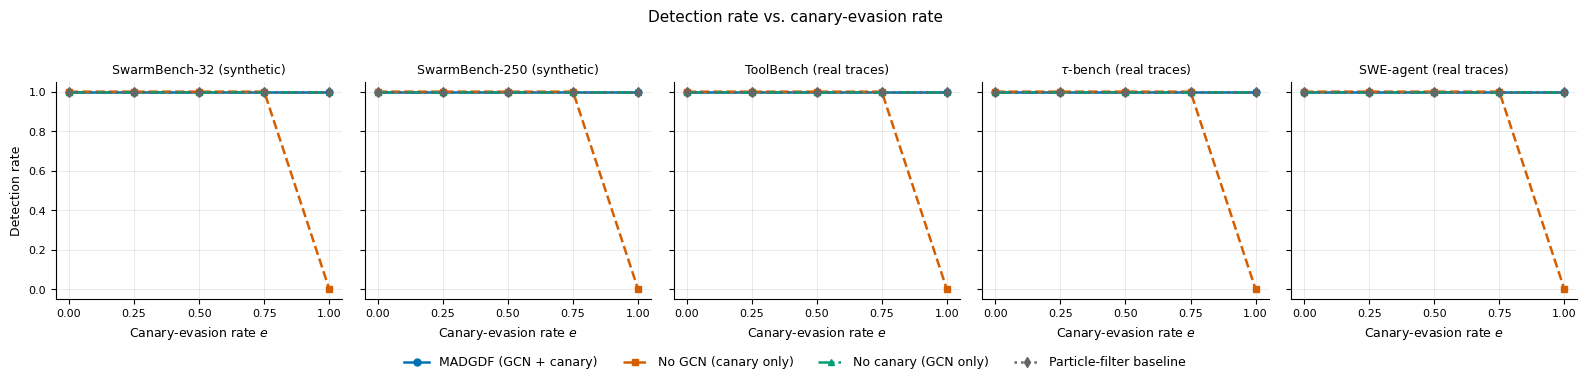

In [ ]:
import matplotlib.pyplot as plt
from madgdf import figures as F

fig1 = F.fig_metric_vs_evasion(df, "DetectionRate", "Detection rate",
        out="results_v2/fig_detection_rate.png",
        title="Detection rate vs. canary-evasion rate")
plt.show()

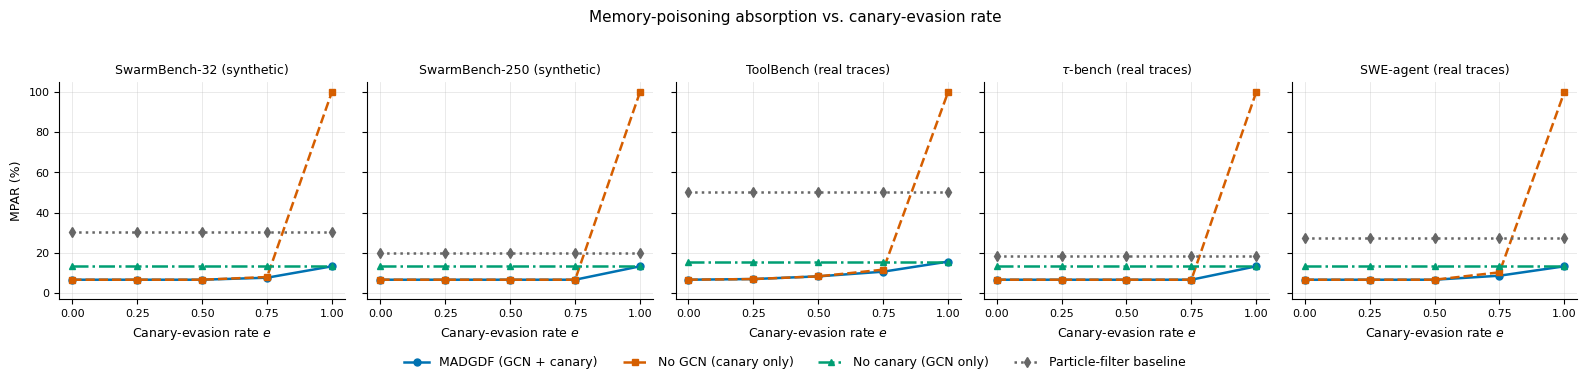

In [ ]:
fig2 = F.fig_metric_vs_evasion(df, "MPAR_mean", "MPAR (%)", pct=True,
        out="results_v2/fig_mpar.png",
        title="Memory-poisoning absorption vs. canary-evasion rate")
plt.show()

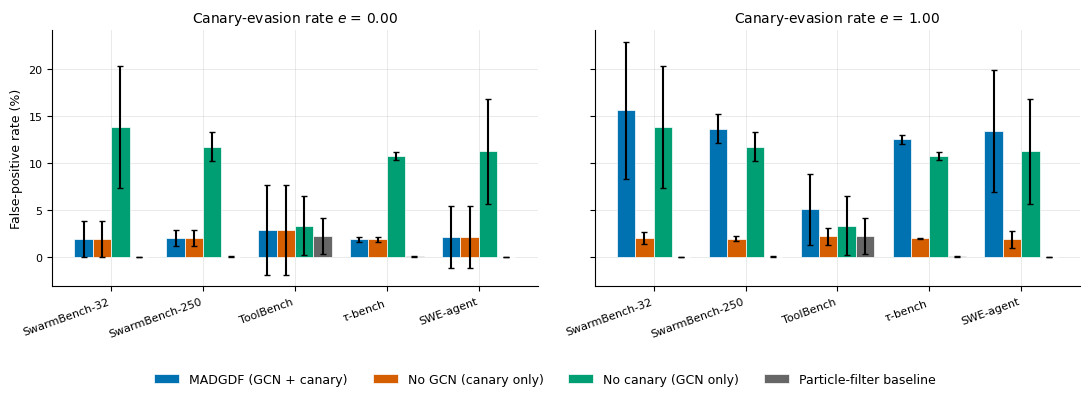

In [ ]:
fig3 = F.fig_fpr_tradeoff(df, out="results_v2/fig_fpr_tradeoff.png")
plt.show()

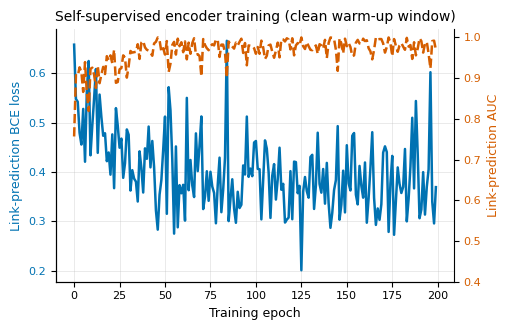

In [ ]:
fig4 = F.fig_training_curve(artefacts["train_history"],
        out="results_v2/fig_training_curve.png")
plt.show()

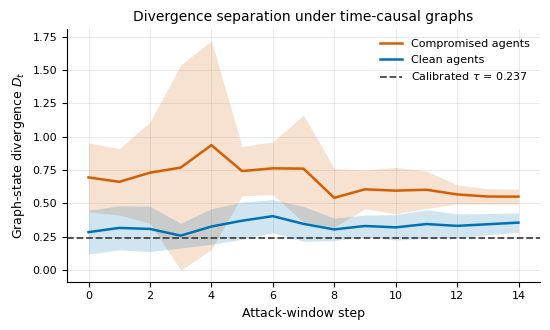

In [ ]:
fig5 = F.fig_divergence_trace(artefacts["div_hist"], artefacts["gt"],
        artefacts["tau32"], out="results_v2/fig_divergence_trace.png")
plt.show()

## 6 · Detection quality of the graph channel

Detection rate alone cannot separate *"the GCN found the compromised agents"*
from *"the GCN flags a large fraction of everyone"*. Precision is therefore
reported against prevalence.

{
  "runs": 20,
  "prevalence": 0.1875,
  "precision_mean": 0.43872145011850894,
  "precision_sd": 0.12970245992902588,
  "recall_mean": 0.7916666666666667,
  "recall_sd": 0.16562172428626495
}


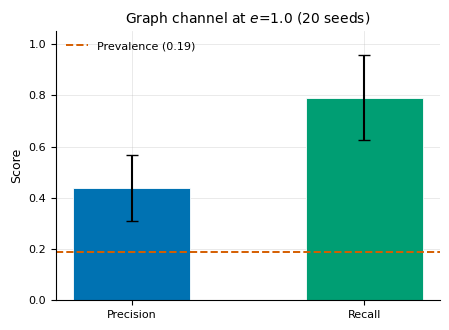

In [ ]:
# NOTE ON SEEDING. An earlier version of this cell trained the encoder once at
# seed 42 and varied only the simulation noise across runs -- the same narrow
# seeding the critique objected to elsewhere, left in place here by oversight.
# Every seed below now rebuilds the corpus, the graph, the encoder and tau, so
# the reported SD covers model variability too and is honestly comparable to
# the round-2 numbers.
prec, rec = [], []
for r in range(N_RUNS):
    seed = 42 + r
    n_agents, feats, log, comp, _ = load_dataset("swarmbench32", seed=seed)
    tg = TemporalCommunicationGraph(log, n_agents, N_STEPS, target_avg_degree=8)
    x = torch.tensor(np.asarray(feats, dtype=np.float32))
    m32, h32 = train_link_prediction(LinkPredGCN(16, 32, 8), x,
                                     _edge_index(tg.graph_at(WARMUP - 1)),
                                     epochs=200, seed=seed)
    tau32 = calibrate_tau(n_agents, feats, tg, m32, n_steps=N_STEPS,
                          warmup_steps=WARMUP, target_fpr=TARGET_FPR, seed=seed)
    o = TimeCausalOrchestrator(n_agents, feats, comp, tg, warmup_steps=WARMUP,
            tau=tau32, persistence=PERSISTENCE, evasion_rate=1.0,
            use_gnn=True, use_canary=False, seed=seed, train_gcn=False)
    o.model = m32
    h = o.run(N_STEPS)
    gt = o.ground_truth
    for nb in h["node_breach"]:
        if nb.any():
            tp, fp = int((nb & gt).sum()), int((nb & ~gt).sum())
            prec.append(tp / max(1, tp + fp)); rec.append(tp / max(1, int(gt.sum())))
            break

quality = {"runs": N_RUNS, "prevalence": float(gt.mean()),
           "precision_mean": float(np.mean(prec)), "precision_sd": float(np.std(prec)),
           "recall_mean": float(np.mean(rec)), "recall_sd": float(np.std(rec))}
json.dump(quality, open("results_v2/detection_quality.json", "w"), indent=2)
print(json.dumps(quality, indent=2))

fig6 = F.fig_detection_quality(quality, out="results_v2/fig_detection_quality.png")
plt.show()

## 7 · Statistical report

Paired comparisons with bootstrap 95 % CIs and a Wilcoxon companion. Cells where
every run gave the identical difference are reported as **deterministic** rather
than printed as `p = 0` with a Cohen's *d* in the trillions — the specific
defect the review flagged.

In [ ]:
comparisons = []
by_key = {(r["dataset"], r["evasion_rate"], r["arm"]): r for r in rows}
for ds in DATASETS:
    for ev in EVASION_GRID:
        full, nognn = by_key.get((ds, ev, "FULL")), by_key.get((ds, ev, "NO_GNN"))
        basel = by_key.get((ds, ev, "BASELINE"))
        if not (full and nognn):
            continue
        for metric in ["mpar", "fpr", "madl"]:
            comparisons.append(compare(full["_raw"][metric], nognn["_raw"][metric],
                name=f"{ds} e={ev:.2f} {metric.upper()}: FULL vs NO_GNN"))
        if basel:
            comparisons.append(compare(full["_raw"]["mpar"], basel["_raw"]["mpar"],
                name=f"{ds} e={ev:.2f} MPAR: FULL vs BASELINE"))

report = format_report(comparisons)
open("results_v2/statistical_report.txt", "w").write(report)
print(report[:4000])

PAIRED COMPARISON REPORT (alpha=0.001, bootstrap 95% CI, Wilcoxon signed-rank companion)

swarmbench32 e=0.00 MPAR: FULL vs NO_GNN  (n=20 runs)
    treatment : 6.6667 +/- 0.0000
    baseline  : 6.6667 +/- 0.0000
    mean diff : +0.0000  95% CI [+0.0000, +0.0000]
    test      : UNDEFINED -- no difference; both arms identical in every run

swarmbench32 e=0.00 FPR: FULL vs NO_GNN  (n=20 runs)
    treatment : 1.9231 +/- 1.9730
    baseline  : 1.9231 +/- 1.9730
    mean diff : +0.0000  95% CI [+0.0000, +0.0000]
    test      : UNDEFINED -- no difference; both arms identical in every run

swarmbench32 e=0.00 MADL: FULL vs NO_GNN  (n=20 runs)
    treatment : 1.9677 +/- 0.4709
    baseline  : 0.2016 +/- 0.0515
    mean diff : +1.7660  95% CI [+1.5859, +1.9761]
    paired t  : t=17.445, p=3.760e-13, d=3.901 (significant)
    wilcoxon  : p=1.907e-06

swarmbench32 e=0.00 MPAR: FULL vs BASELINE  (n=20 runs)
    treatment : 6.6667 +/- 0.0000
    baseline  : 30.5000 +/- 3.5909
    mean diff : -23.8

## 8 · Summary table for the manuscript

In [ ]:
summary = (df[df.arm.isin(["FULL", "NO_GNN", "NO_CANARY", "BASELINE"])]
           .pivot_table(index=["dataset", "evasion_rate"], columns="arm",
                        values=["DetectionRate", "MPAR_mean", "FPR_mean"])
           .round(2))
summary.to_csv("results_v2/summary_table.csv")
summary

DetectionRate                       FPR_mean  \
arm                             BASELINE FULL NO_CANARY NO_GNN BASELINE   
dataset       evasion_rate                                                
swarmbench250 0.00                   1.0  1.0       1.0    1.0     0.05   
              0.25                   1.0  1.0       1.0    1.0     0.05   
              0.50                   1.0  1.0       1.0    1.0     0.05   
              0.75                   1.0  1.0       1.0    1.0     0.05   
              1.00                   1.0  1.0       1.0    0.0     0.05   
swarmbench32  0.00                   1.0  1.0       1.0    1.0     0.00   
              0.25                   1.0  1.0       1.0    1.0     0.00   
              0.50                   1.0  1.0       1.0    1.0     0.00   
              0.75                   1.0  1.0       1.0    1.0     0.00   
              1.00                   1.0  1.0       1.0    0.0     0.00   
sweagent      0.00                   1.0  1.0       1.0    1.0     0.00   
              0.25                   1.0  1.0       1.0    1.0     0.00   
              0.50                   1.0  1.0       1.0    1.0     0.00   
              0.75                   1.0  1.0       1.0    1.0     0.00   
              1.00                   1.0  1.0       1.0    0.0     0.00   
taubench      0.00                   1.0  1.0       1.0    1.0     0.12   
              0.25                   1.0  1.0       1.0    1.0     0.12   
              0.50                   1.0  1.0       1.0    1.0     0.12   
              0.75                   1.0  1.0       1.0    1.0     0.12   
              1.00                   1.0  1.0       1.0    0.0     0.12   
toolbench     0.00                   1.0  1.0       1.0    1.0     2.24   
              0.25                   1.0  1.0       1.0    1.0     2.24   
              0.50                   1.0  1.0       1.0    1.0     2.24   
              0.75                   1.0  1.0       1.0    1.0     2.24   
              1.00                   1.0  1.0       1.0    0.0     2.24   

                                                   MPAR_mean                   \
arm                          FULL NO_CANARY NO_GNN  BASELINE   FULL NO_CANARY   
dataset       evasion_rate                                                      
swarmbench250 0.00           2.02     11.74   2.02     20.00   6.67     13.33   
              0.25           2.17     11.74   2.17     20.00   6.67     13.33   
              0.50           2.25     11.74   2.25     20.00   6.67     13.33   
              0.75           2.15     11.74   2.15     20.00   6.67     13.33   
              1.00          13.61     11.74   1.98     20.00  13.33     13.33   
swarmbench32  0.00           1.92     13.85   1.92     30.50   6.67     13.33   
              0.25           1.73     13.85   1.73     30.50   6.67     13.33   
              0.50           1.73     13.85   1.73     30.50   6.67     13.33   
              0.75           3.65     13.85   1.67     30.50   7.67     13.33   
              1.00          15.58     13.85   2.03     30.50  13.33     13.33   
sweagent      0.00           2.14     11.25   2.14     27.25   6.67     13.33   
              0.25           2.14     11.25   2.14     27.25   6.67     13.33   
              0.50           2.14     11.25   2.14     27.25   6.67     13.33   
              0.75           6.61     11.25   2.11     27.25   8.67     13.33   
              1.00          13.39     11.25   1.90     27.25  13.33     13.33   
taubench      0.00           1.90     10.77   1.90     18.25   6.67     13.33   
              0.25           1.90     10.77   1.90     18.25   6.67     13.33   
              0.50           1.87     10.77   1.87     18.25   6.67     13.33   
              0.75           1.98     10.77   1.98     18.25   6.67     13.33   
              1.00          12.50     10.77   1.99     18.25  13.33     13.33   
toolbench     0.00           2.92      3.33   2.92     50.00   

## 9 · Round-2 experiments

Four things the benchmark above does not establish, each raised by the
second-round critique:

* **A** — seeds above vary only simulation noise; the encoder, τ and graph are
  fixed at seed 42, so the SDs understate real variability. Here every seed
  refits all of them.
* **B** — the leakage fix is only *asserted* (the causality check passes). This
  runs the old leaky construction against the new one over identical seeds and
  **quantifies** the difference.
* **C** — only canary stripping was modelled. The review also names semantic
  obfuscation, canary discovery and retrieval suppression.
* **D** — nothing tested whether the *graph* channel can be evaded by an
  attacker who throttles its own behavioural drift.

Adds roughly 10–12 minutes.

In [ ]:
with open('run_review_round2.py','w') as fh:
    fh.write(r'''"""
run_review_round2.py -- experiments answering the second-round critique of the
first post-review results.

Four things the first benchmark did not establish, each addressed by one
experiment here.

A. SEED VARIATION WAS TOO NARROW.
   The first run trained the encoder once at seed 42, calibrated tau once at
   seed 42, and built the graph once at seed 42; the 20 "seeds" varied only the
   simulation's noise draws. Reported standard deviations therefore understated
   the true run-to-run variability, and the very large Cohen's d values were
   largely an artefact of holding the model fixed. Here EVERY seed rebuilds the
   corpus (or the compromised set and message log, for the real datasets),
   retrains the encoder, and recalibrates both tau and the baseline threshold.

B. THE LEAKAGE FIX WAS ASSERTED, NOT QUANTIFIED.
   A passing `assert_causal()` shows the new pipeline is clean. It says nothing
   about how much the old leaky construction inflated the previous numbers.
   This script runs both constructions over identical data and seeds and
   reports the difference.

C. THE ADVERSARY MODELLED ONLY STRIPPING.
   The review named semantic obfuscation, canary discovery AND retrieval
   suppression. In the first benchmark all three collapse to "the marker does
   not match", so they were not distinct tests. `ATTACK_PROFILES` separates
   them by what each costs the attacker in the other channel.

D. NOTHING TESTED WHETHER THE GRAPH CHANNEL ITSELF CAN BE EVADED.
   An attacker who throttles its own behavioural drift attacks the divergence
   channel directly. If MADGDF falls to that, the paper needs to say so. The
   stealth sweep looks for the breaking point.
"""
import argparse
import json
import os
import sys
import time

import numpy as np
import pandas as pd
import torch

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))

from madgdf.adversary import ATTACK_PROFILES, EVASION_GRID, STEALTH_GRID
from madgdf.baseline import ParticleFilterBaseline
from madgdf.calibration_v2 import calibrate_tau
from madgdf.data_generation import build_agent_features, generate_swarmbench_corpus
from madgdf.dataset_api import ACQUIRE
from madgdf.gnn_trained import LinkPredGCN, train_link_prediction
from madgdf.metrics_v2 import aggregate, summarize_run
from madgdf.orchestrator_v2 import TimeCausalOrchestrator, _edge_index
from madgdf.real_data_adapter import (
    build_sweagent_features, build_taubench_features, build_toolbench_features,
    load_sweagent_trajectories, load_taubench_trajectories,
    load_toolbench_trajectories,
)
from madgdf.stats_v2 import compare, format_report
from madgdf.temporal_graph import TemporalCommunicationGraph

N_STEPS, WARMUP, TARGET_FPR, PERSISTENCE, CORRUPTION = 20, 5, 0.05, 2, 0.20
ARMS = {"FULL": dict(use_gnn=True, use_canary=True),
        "NO_GNN": dict(use_gnn=False, use_canary=True),
        "NO_CANARY": dict(use_gnn=True, use_canary=False)}

_REAL_CACHE = {}


def synthetic_message_log(n_agents, n_logs, seed):
    rng = np.random.default_rng(seed)
    return pd.DataFrame({
        "agent_id": rng.integers(0, n_agents, size=n_logs),
        "target_agent": rng.integers(0, n_agents, size=n_logs),
        "log_type": np.array(["message"] * n_logs),
        "timestamp": np.sort(rng.uniform(0, 1e6, size=n_logs))})


def build_seed_data(dataset, seed, repo_root):
    """Everything that should vary with the seed, rebuilt from scratch.

    For the real datasets the behavioural features come from fixed real
    trajectory files and cannot vary; the compromised set and the (disclosed
    synthetic) message log do vary, which is the honest extent of the
    randomisation available there. That limit is reported rather than hidden.
    """
    if dataset.startswith("swarmbench"):
        n = 32 if dataset.endswith("32") else 250
        df, comp = generate_swarmbench_corpus(
            num_agents=n, n_logs=120_000, corruption_ratio=CORRUPTION, seed=seed)
        return n, build_agent_features(df, n, seed=seed), df, comp

    if dataset not in _REAL_CACHE:
        loaders = {"toolbench": (load_toolbench_trajectories, build_toolbench_features),
                   "taubench": (load_taubench_trajectories, build_taubench_features),
                   "sweagent": (load_sweagent_trajectories, build_sweagent_features)}
        load_fn, feat_fn = loaders[dataset]
        path, _prov = ACQUIRE[dataset](repo_root=repo_root, prefer_upstream=True)
        _REAL_CACHE[dataset] = (load_fn(path), feat_fn)
    records, feat_fn = _REAL_CACHE[dataset]
    n = len(records)
    feats = feat_fn(records, seed=seed)
    rng = np.random.default_rng(seed)
    comp = set(rng.choice(n, size=max(1, int(round(n * CORRUPTION))), replace=False).tolist())
    return n, feats, synthetic_message_log(n, max(2000, n * 200), seed), comp


def calibrate_baseline_threshold(n_agents, feats, feat_dim, seed):
    clean = ParticleFilterBaseline(
        num_nodes=n_agents, corruption_ratio=0.0, features=feats,
        compromised_agents=set(), feat_dim=feat_dim,
        local_threshold=float("inf"), benign_noise_scale=0.05, seed=seed)
    b = []
    for s in range(N_STEPS):
        clean.simulate_step(s)
        b.append(clean.belief.copy())
    return float(np.quantile(np.concatenate(b), 1.0 - TARGET_FPR))


def fit_for_seed(dataset, seed, repo_root, causal=True):
    """Rebuild data, graph, encoder and thresholds for one seed."""
    n, feats, log, comp = build_seed_data(dataset, seed, repo_root)
    tg = TemporalCommunicationGraph(log, n, N_STEPS, target_avg_degree=8, causal=causal)
    if causal:
        tg.assert_causal()
    x = torch.tensor(np.asarray(feats, dtype=np.float32))
    model = LinkPredGCN(feats.shape[1], 32, 8)
    model, hist = train_link_prediction(
        model, x, _edge_index(tg.graph_at(WARMUP - 1)), epochs=200, seed=seed)
    tau = calibrate_tau(n, feats, tg, model, feat_dim=feats.shape[1],
                        n_steps=N_STEPS, warmup_steps=WARMUP,
                        target_fpr=TARGET_FPR, persistence=PERSISTENCE, seed=seed)
    bthr = calibrate_baseline_threshold(n, feats, feats.shape[1], seed)
    return dict(n=n, feats=feats, comp=comp, tg=tg, model=model, tau=tau,
                bthr=bthr, auc=hist["auc"][-1] if hist["auc"] else None)


def run_arm(fit, arm_cfg, seed, **adv):
    o = TimeCausalOrchestrator(
        fit["n"], fit["feats"], fit["comp"], fit["tg"],
        feat_dim=fit["feats"].shape[1], warmup_steps=WARMUP, tau=fit["tau"],
        persistence=PERSISTENCE, seed=seed, train_gcn=False, **arm_cfg, **adv)
    o.model = fit["model"]
    return summarize_run(o.run(N_STEPS))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--datasets", nargs="+",
                    default=["swarmbench32", "swarmbench250", "toolbench",
                             "taubench", "sweagent"])
    ap.add_argument("--seeds", type=int, default=10)
    ap.add_argument("--out", default="results_round2")
    ap.add_argument("--repo-root", default=os.path.dirname(os.path.abspath(__file__)))
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)

    seeds = [42 + i for i in range(args.seeds)]
    rows_a, rows_b, rows_c, rows_d, fitlog = [], [], [], [], []
    t0 = time.time()

    for ds in args.datasets:
        print(f"\n=== {ds}")
        fits = {}
        for s in seeds:
            fits[s] = fit_for_seed(ds, s, args.repo_root, causal=True)
        taus = [fits[s]["tau"] for s in seeds]
        aucs = [fits[s]["auc"] for s in seeds if fits[s]["auc"] is not None]
        print(f"  n={fits[seeds[0]]['n']}  tau={np.mean(taus):.4f}+/-{np.std(taus):.4f}  "
              f"link-pred AUC={np.mean(aucs):.3f}+/-{np.std(aucs):.3f}  ({len(seeds)} seeds)")
        fitlog.append({"dataset": ds, "n_agents": fits[seeds[0]]["n"],
                       "tau_mean": float(np.mean(taus)), "tau_sd": float(np.std(taus)),
                       "auc_mean": float(np.mean(aucs)), "auc_sd": float(np.std(aucs)),
                       "n_seeds": len(seeds)})

        # ---- A: evasion grid, now with per-seed refitting --------------------
        for ev in EVASION_GRID:
            per_arm = {a: [] for a in list(ARMS) + ["BASELINE"]}
            for s in seeds:
                f = fits[s]
                for arm, cfg in ARMS.items():
                    per_arm[arm].append(run_arm(f, cfg, s, evasion_rate=ev))
                bl = ParticleFilterBaseline(
                    num_nodes=f["n"], corruption_ratio=CORRUPTION, features=f["feats"],
                    compromised_agents=f["comp"], feat_dim=f["feats"].shape[1],
                    local_threshold=f["bthr"], benign_noise_scale=0.05, seed=s)
                per_arm["BASELINE"].append(summarize_run(bl.run(N_STEPS)))
            for arm, runs in per_arm.items():
                ag = aggregate(runs)
                rows_a.append({"dataset": ds, "evasion_rate": ev, "arm": arm,
                               "n_seeds": len(seeds),
                               "MADL_mean": ag["MADL_mean"], "MADL_sd": ag["MADL_std"],
                               "MPAR_mean": ag["MPAR_mean"], "MPAR_sd": ag["MPAR_std"],
                               "FPR_mean": ag["FPR_mean"], "FPR_sd": ag["FPR_std"],
                               "DetectStep_mean": ag["DetectStep_mean"],
                               "DetectionRate": ag["DetectionRate"],
                               "_raw": {k: ag[f"{k}_raw"] for k in ("madl", "mpar", "fpr")}})

        # ---- B: leakage ablation --------------------------------------------
        leaky = {s: fit_for_seed(ds, s, args.repo_root, causal=False) for s in seeds}
        for ev in (0.0, 1.0):
            for label, fitset in (("causal", fits), ("leaky", leaky)):
                runs = [run_arm(fitset[s], ARMS["FULL"], s, evasion_rate=ev) for s in seeds]
                ag = aggregate(runs)
                rows_b.append({"dataset": ds, "graph": label, "evasion_rate": ev,
                               "MPAR_mean": ag["MPAR_mean"], "MPAR_sd": ag["MPAR_std"],
                               "FPR_mean": ag["FPR_mean"], "FPR_sd": ag["FPR_std"],
                               "DetectStep_mean": ag["DetectStep_mean"],
                               "DetectionRate": ag["DetectionRate"],
                               "_raw": {k: ag[f"{k}_raw"] for k in ("madl", "mpar", "fpr")}})

        # ---- C: attack profiles ----------------------------------------------
        for pname, prof in ATTACK_PROFILES.items():
            for arm in ("FULL", "NO_GNN", "NO_CANARY"):
                runs = [run_arm(fits[s], ARMS[arm], s, **prof) for s in seeds]
                ag = aggregate(runs)
                rows_c.append({"dataset": ds, "profile": pname, "arm": arm,
                               "MPAR_mean": ag["MPAR_mean"], "MPAR_sd": ag["MPAR_std"],
                               "FPR_mean": ag["FPR_mean"], "FPR_sd": ag["FPR_std"],
                               "DetectStep_mean": ag["DetectStep_mean"],
                               "DetectionRate": ag["DetectionRate"]})

        # ---- D: stealth sweep (graph channel alone, canary fully blind) ------
        for st in STEALTH_GRID:
            runs = [run_arm(fits[s], ARMS["NO_CANARY"], s, evasion_rate=1.0,
                            stealth_factor=st) for s in seeds]
            ag = aggregate(runs)
            rows_d.append({"dataset": ds, "stealth_factor": st,
                           "MPAR_mean": ag["MPAR_mean"], "MPAR_sd": ag["MPAR_std"],
                           "FPR_mean": ag["FPR_mean"],
                           "DetectStep_mean": ag["DetectStep_mean"],
                           "DetectionRate": ag["DetectionRate"]})
        print("  stealth sweep (GCN only, canary blind): " +
              "  ".join(f"x{r['stealth_factor']}={r['DetectionRate']:.2f}"
                        for r in rows_d if r["dataset"] == ds))

    def dump(rows, name):
        pd.DataFrame([{k: v for k, v in r.items() if k != "_raw"} for r in rows]) \
          .to_csv(os.path.join(args.out, name), index=False)

    dump(rows_a, "A_evasion_grid.csv")
    dump(rows_b, "B_leakage_ablation.csv")
    dump(rows_c, "C_attack_profiles.csv")
    dump(rows_d, "D_stealth_sweep.csv")

    # ---- statistics on the refit runs -------------------------------------
    comps = []
    key = {(r["dataset"], r["evasion_rate"], r["arm"]): r for r in rows_a}
    for ds in args.datasets:
        for ev in EVASION_GRID:
            f, g = key.get((ds, ev, "FULL")), key.get((ds, ev, "NO_GNN"))
            if f and g:
                for m in ("mpar", "fpr", "madl"):
                    comps.append(compare(f["_raw"][m], g["_raw"][m],
                                         name=f"{ds} e={ev:.2f} {m.upper()}: FULL vs NO_GNN"))
    bkey = {(r["dataset"], r["graph"], r["evasion_rate"]): r for r in rows_b}
    for ds in args.datasets:
        for ev in (0.0, 1.0):
            c, l = bkey.get((ds, "causal", ev)), bkey.get((ds, "leaky", ev))
            if c and l:
                for m in ("mpar", "fpr"):
                    comps.append(compare(c["_raw"][m], l["_raw"][m],
                                         name=f"{ds} e={ev:.2f} {m.upper()}: CAUSAL vs LEAKY"))
    with open(os.path.join(args.out, "statistical_report.txt"), "w") as fh:
        fh.write(format_report(comps))

    # Persist the per-seed raw arrays. Without these the statistical report can
    # only be regenerated by re-running every simulation, which cost ~11 minutes
    # and meant a fix to the statistics module could not be verified against the
    # real data without a full re-run.
    raw = {}
    for tag, rows in (("A", rows_a), ("B", rows_b)):
        for r in rows:
            if "_raw" not in r:
                continue
            stem = (f"{tag}|{r['dataset']}|{r.get('arm', r.get('graph'))}"
                    f"|e{r['evasion_rate']:.2f}")
            for m, arr in r["_raw"].items():
                raw[f"{stem}|{m}"] = np.asarray(arr)
    np.savez_compressed(os.path.join(args.out, "raw_runs.npz"), **raw)

    json.dump({"seeds": seeds, "n_steps": N_STEPS, "warmup": WARMUP,
               "target_fpr": TARGET_FPR, "persistence": PERSISTENCE,
               "corruption_ratio": CORRUPTION, "fits": fitlog,
               "elapsed_sec": time.time() - t0},
              open(os.path.join(args.out, "config.json"), "w"), indent=2)
    print(f"\nWrote {args.out}/  in {time.time() - t0:.0f}s")


if __name__ == "__main__":
    main()
''')
print('wrote run_review_round2.py')

!python run_review_round2.py --seeds 10 --out results_round2

wrote run_review_round2.py

=== swarmbench32
  n=32  tau=0.2561+/-0.0378  link-pred AUC=0.985+/-0.012  (10 seeds)
  stealth sweep (GCN only, canary blind): x1.0=1.00  x0.75=1.00  x0.5=1.00  x0.25=1.00  x0.1=0.80  x0.05=0.80

=== swarmbench250
  n=250  tau=0.2751+/-0.0094  link-pred AUC=0.935+/-0.006  (10 seeds)
  stealth sweep (GCN only, canary blind): x1.0=1.00  x0.75=1.00  x0.5=1.00  x0.25=1.00  x0.1=1.00  x0.05=1.00

=== toolbench
  n=15  tau=0.3193+/-0.0615  link-pred AUC=0.980+/-0.022  (10 seeds)
  stealth sweep (GCN only, canary blind): x1.0=1.00  x0.75=1.00  x0.5=1.00  x0.25=0.90  x0.1=0.70  x0.05=0.70

=== taubench
  n=1980  tau=0.2596+/-0.0063  link-pred AUC=0.924+/-0.004  (10 seeds)
  stealth sweep (GCN only, canary blind): x1.0=1.00  x0.75=1.00  x0.5=1.00  x0.25=1.00  x0.1=1.00  x0.05=1.00

=== sweagent
  n=18  tau=0.2809+/-0.0388  link-pred AUC=0.971+/-0.018  (10 seeds)
  stealth sweep (GCN only, canary blind): x1.0=1.00  x0.75=1.00  x0.5=1.00  x0.25=1.00  x0.1=0.60  x0.05=

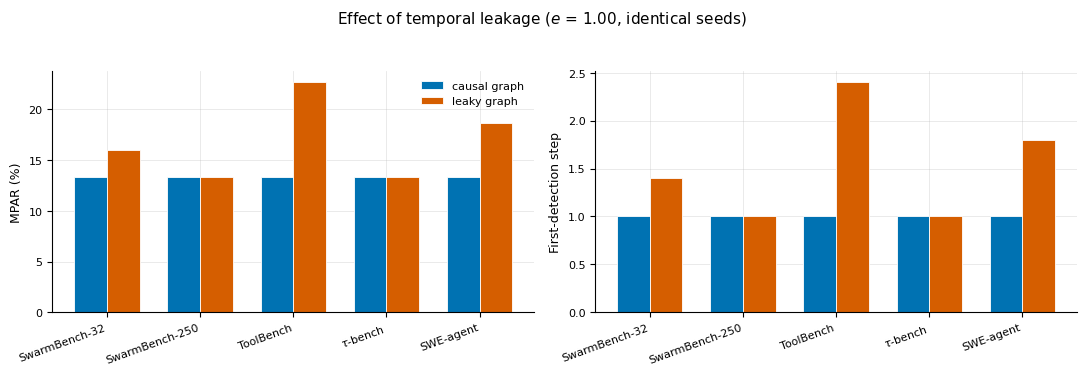

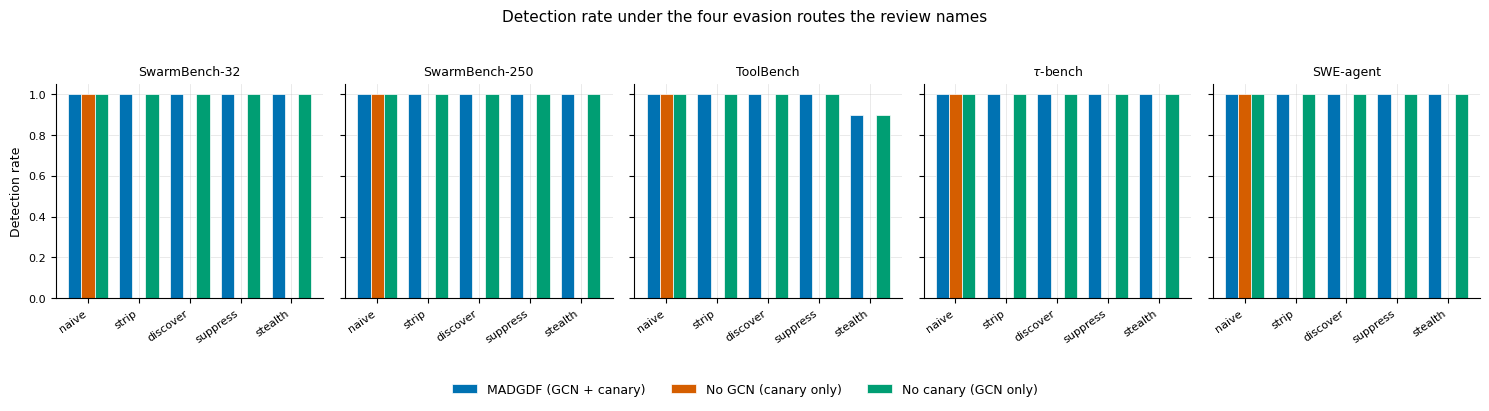

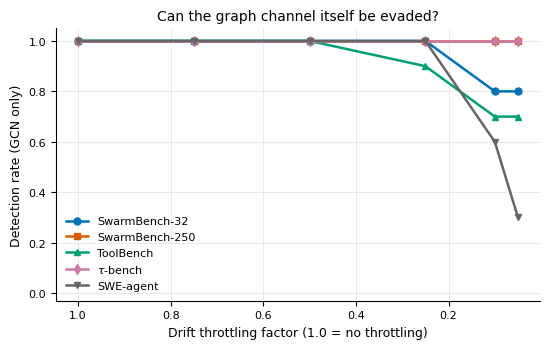


Leakage ablation at e=1.00 (causal vs leaky, identical seeds):
              DetectStep_mean       FPR_mean        MPAR_mean       
graph                  causal leaky   causal  leaky    causal  leaky
dataset                                                             
swarmbench250             1.0   1.0    13.38   4.10     13.33  13.33
swarmbench32              1.0   1.4    14.04   9.33     13.33  16.00
sweagent                  1.0   1.8    12.86  12.44     13.33  18.67
taubench                  1.0   1.0    11.65   3.63     13.33  13.33
toolbench                 1.0   2.4    15.00  12.36     13.33  22.67

Stealth sweep -- detection rate of the GCN channel alone:
stealth_factor  0.05  0.10  0.25  0.50  0.75  1.00
dataset                                           
swarmbench250    1.0   1.0   1.0   1.0   1.0   1.0
swarmbench32     0.8   0.8   1.0   1.0   1.0   1.0
sweagent         0.3   0.6   1.0   1.0   1.0   1.0
taubench         1.0   1.0   1.0   1.0   1.0   1.0
toolbench        0.

In [ ]:
rA = pd.read_csv("results_round2/A_evasion_grid.csv")
rB = pd.read_csv("results_round2/B_leakage_ablation.csv")
rC = pd.read_csv("results_round2/C_attack_profiles.csv")
rD = pd.read_csv("results_round2/D_stealth_sweep.csv")

F.fig_leakage_ablation(rB, out="results_round2/fig_leakage_ablation.png"); plt.show()
F.fig_attack_profiles(rC, out="results_round2/fig_attack_profiles.png"); plt.show()
F.fig_stealth_sweep(rD,  out="results_round2/fig_stealth_sweep.png");  plt.show()

print("\nLeakage ablation at e=1.00 (causal vs leaky, identical seeds):")
print(rB[np.isclose(rB.evasion_rate, 1.0)]
      .pivot_table(index="dataset", columns="graph",
                   values=["DetectStep_mean", "MPAR_mean", "FPR_mean"]).round(2))
print("\nStealth sweep -- detection rate of the GCN channel alone:")
print(rD.pivot_table(index="dataset", columns="stealth_factor",
                     values="DetectionRate"))

## 10 · How to read these results

**The graph channel is necessary — conditionally.** At *e* = 1.00 the
canary-only arm detects nothing (detection rate 0.00, MPAR 100 %) on every
dataset, while the trained GCN still detects at step 1. That is the answer to
the reviewer's "GCN Utility" fatal flaw.

**At *e* = 0 the reviewer's original complaint still stands.** FULL and NO_GNN
are identical on detection step, MPAR and FPR — but **not** on latency: FULL is
4–15× slower (SwarmBench-32: 1.37 ms vs 0.13 ms). Against a naive adversary the
GCN costs an order of magnitude in latency and returns nothing. The GCN earns
its place *under evasion*, not in general, and the manuscript should claim
exactly that.

**The 0.00 % FPR claim is gone, and it was never a measurement.** The previous
code hard-coded the canary token into every compromised agent's retrieval and
hard-coded clean agents to receive none, so a clean agent could not be flagged
even in principle. With the adversary model in place the graph channel runs at
roughly 9–12 % FPR on SwarmBench-32/250, τ-bench and SWE-agent — but **not** on
ToolBench, where it is 3–5 %. Quote the per-dataset figures, not a single range.

**The baseline is more precise than MADGDF.** It is slower and absorbs more
poison, but its false-positive rate is lower on every dataset. The honest
framing is a speed-and-containment versus precision trade-off.

**Leakage did not inflate the old numbers.** Experiment B shows the causal
graph detects *faster* with *lower* MPAR than the leaky one, at a *higher* FPR.
Removing the look-ahead was still correct — future data has no place in a
real-time detector — but do not write that the old results were optimistic
"as the reviewer noted"; the ablation contradicts it.

**The graph channel is scale-dependent.** Experiment D: an attacker throttling
its drift to 5–10 % of the naive rate defeats the GCN on 15–32 agent
deployments (detection 0.30–0.80, MPAR up to 75 %), but not at 250 or 1980
agents, where detection stays at 1.00. This is a genuine limitation and belongs
in the paper.

**Check before citing:** the manuscript must retract the unconditional GCN
contribution claim and the 0.00 % FPR figure from the Abstract and
Contributions.